# UTS Data Wrangling RAVA DWI ANDIKA (25031554039)
## Dari Data Mentah ke Dataset Siap Analisis: Harga Pangan Jawa Timur 2024

## Persiapan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import re
import warnings

from pathlib import Path
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("Libraries berhasil diimport.")
print("Persiapan project berhasil.")

Libraries berhasil diimport.
Persiapan project berhasil.


## Path File

In [4]:
DATA_DIR = Path("UTS_DW_data")
HARGA_DIR = DATA_DIR / "1_harga_pasar_tradisional"
CUACA_DIR = DATA_DIR / "2_cuaca_stasiun"
WILAYAH_DIR = DATA_DIR / "3_wilayah"

OUTPUT_DIR = Path("data_processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Tahap 3. Membaca dan Menstrukturkan Data

### Tahap 3a. Membaca semua sumber data

In [5]:
file_harga = HARGA_DIR / "pihps_pasar_tradisional_jatim_2024.xlsx"

data_harga = pd.read_excel(
    file_harga,
    sheet_name=None
)

file_cuaca = CUACA_DIR / "noaa_gsod_jatim_2024.csv"
data_cuaca = pd.read_csv(file_cuaca)
data_kode = pd.read_csv(WILAYAH_DIR / "kode_wilayah_jatim.csv")
data_penduduk = pd.read_csv(WILAYAH_DIR / "penduduk_jatim.csv")
data_luas = pd.read_csv(WILAYAH_DIR / "luas_jatim.csv")

In [4]:
print("DATA HARGA PIHPS")

for nama_sheet, df in data_harga.items():
    print(f"{nama_sheet}: {df.shape[0]} baris × {df.shape[1]} kolom")

print("\nDATA CUACA NOAA")
print(f"Dimensi: {data_cuaca.shape[0]} baris × {data_cuaca.shape[1]} kolom")

print("\nDATA WILAYAH KEPMENDAGRI")
print(f"Kode wilayah : {data_kode.shape[0]} baris × {data_kode.shape[1]} kolom")
print(f"Data penduduk: {data_penduduk.shape[0]} baris × {data_penduduk.shape[1]} kolom")
print(f"Data luas    : {data_luas.shape[0]} baris × {data_luas.shape[1]} kolom")

DATA HARGA PIHPS
Kab. Banyuwangi: 28 baris × 265 kolom
Kab. Jember: 27 baris × 265 kolom
Kab. Sumenep: 31 baris × 265 kolom
Kota Blitar: 30 baris × 265 kolom
Kota Kediri: 29 baris × 265 kolom
Kota Madiun: 29 baris × 265 kolom
Kota Malang: 31 baris × 265 kolom
Kota Probolinggo: 30 baris × 265 kolom
Kota Surabaya: 31 baris × 265 kolom

DATA CUACA NOAA
Dimensi: 1228 baris × 19 kolom

DATA WILAYAH KEPMENDAGRI
Kode wilayah : 9199 baris × 2 kolom
Data penduduk: 39 baris × 5 kolom
Data luas    : 39 baris × 3 kolom


In [5]:
nama_sheet_pertama = list(data_harga.keys())[0]

print("Contoh Data PIHPS:", nama_sheet_pertama)
display(data_harga[nama_sheet_pertama].head(2))

print("\nContoh Data NOAA")
display(data_cuaca.head(2))

print("\nContoh Data Kode Wilayah")
display(data_kode.head(2))

print("\nContoh Data Penduduk")
display(data_penduduk.head(2))

print("\nContoh Data Luas Wilayah")
display(data_luas.head(2))

Contoh Data PIHPS: Kab. Banyuwangi


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,500","13,800","13,900","13,900","13,900","13,900","13,900","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,850","14,850","15,000","15,000","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,550","14,550","14,550","14,550","14,550","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,250",-,"13,250","13,250","13,250","13,950","13,950","13,950","13,950","13,950","13,950","13,950",


Contoh Data NOAA


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,PRCP,SLP,SNDP,STP,TEMP,VISIB,WDSP
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-02,77.4,0,999.9,94.3,81.3,5.1,0.0,1008.4,999.9,7.9,86.5,5.9,2.8
1,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-05,76.8,0,999.9,92.8,78.6,8.0,0.0,1009.9,999.9,9.4,83.9,5.1,2.6



Contoh Data Kode Wilayah


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan



Contoh Data Penduduk


,kode,nama,pria,wanita,total
0,35.00,Jawa Timur,20894359,21025547,41919906
1,35.01,Kabupaten Pacitan,294808,293910,588718



Contoh Data Luas Wilayah


,kode,nama,luas
0,35.00,Jawa Timur,48055.876
1,35.01,Kabupaten Pacitan,1434.818


### Tahap 3b. Mengubah Data Harga PIHPS dari Format Wide menjadi Long

In [6]:
for nama_sheet, df in data_harga.items():
    print(f"\nSHEET: {nama_sheet}")
    print("Dimensi:", df.shape)
    print("Nama kolom:")
    print(df.columns.tolist()[:15])
    display(df.head(2))


SHEET: Kab. Banyuwangi
Dimensi: (28, 265)
Nama kolom:
['no', 'name', 'level', '01/01/2024', '02/01/2024', '03/01/2024', '04/01/2024', '05/01/2024', '08/01/2024', '09/01/2024', '10/01/2024', '11/01/2024', '12/01/2024', '15/01/2024', '16/01/2024']


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,500","13,800","13,900","13,900","13,900","13,900","13,900","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,850","14,850","15,000","15,000","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,550","14,550","14,550","14,550","14,550","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,250",-,"13,250","13,250","13,250","13,950","13,950","13,950","13,950","13,950","13,950","13,950",


SHEET: Kab. Jember
Dimensi: (27, 265)
Nama kolom:
['no', 'name', 'level', '01/01/2024', '02/01/2024', '03/01/2024', '04/01/2024', '05/01/2024', '08/01/2024', '09/01/2024', '10/01/2024', '11/01/2024', '12/01/2024', '15/01/2024', '16/01/2024']


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"13,700","13,700","13,700","13,700","13,700","13,700","14,250","14,250","14,250","14,250","14,300","14,300","14,600","14,600","14,600","14,600","14,600","14,600","14,600","14,700","14,700","14,700","14,700","14,700","14,800","14,800","14,850","14,850","14,850","14,850","15,250","15,250","15,250","15,450","15,500","15,650","15,450","15,500","15,500","15,750","15,500","15,500","15,500","15,500","15,500","15,500","15,650","15,550","15,550","15,550","15,550","15,550","15,450","15,450","15,450","15,450","15,450","15,450","15,450","15,450","15,450","15,450","14,950","14,850","14,850","14,800","14,800","14,800","14,800","14,800","14,800","14,800","14,800","14,800","14,800","14,800","15,300","15,300","15,500","15,300","15,000","15,350","15,200","15,350","15,350","15,200","15,200","15,200","15,200","15,200","14,000","14,000","14,000","14,000","14,000","13,850","13,850","13,850","13,850","13,850","13,850","13,850","13,850","13,850","13,850","13,550","13,550","13,500","13,300","13,300","13,850","13,900","13,900","13,900","13,800","13,650","13,750","13,800","13,700","13,700","13,700","1


SHEET: Kab. Sumenep
Dimensi: (31, 265)
Nama kolom:
['no', 'name', 'level', '01/01/2024', '02/01/2024', '03/01/2024', '04/01/2024', '05/01/2024', '08/01/2024', '09/01/2024', '10/01/2024', '11/01/2024', '12/01/2024', '15/01/2024', '16/01/2024']


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"14,250","14,250","14,250","14,250","14,250","14,250","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","15,650","15,650","15,650","15,650","15,750","15,750","15,750","15,750","15,750","15,750","15,750","15,900","15,900","15,900","15,900","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,700","15,050","15,050","15,050","15,050","15,050","15,050","15,050","14,050","14,050","14,050","14,050","14,050","14,050","14,050","14,050","14,050","13,650","13,700","13,700","13,700","13,600","13,450","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,500","12,350","12,350","12,350","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","12,250","1

... (8 outputs left out)


SHEET: Kota Probolinggo
Dimensi: (30, 265)
Nama kolom:
['no', 'name', 'level', '01/01/2024', '02/01/2024', '03/01/2024', '04/01/2024', '05/01/2024', '08/01/2024', '09/01/2024', '10/01/2024', '11/01/2024', '12/01/2024', '15/01/2024', '16/01/2024']


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","13,700","14,100","14,100","14,100","14,100","14,600","14,600","14,600","14,600","14,600","14,600","14,750","14,750","14,750","14,750","14,750","14,750","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,550","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,650","14,150","14,150","14,150","14,150","14,150","14,150","14,150","14,150","14,150","13,900","13,650","13,650","13,650","13,650","13,650","13,650","13,650","13,650","13,650","13,650","13,150","13,150","13,150","13,150","13,150","13,150","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,550","13,600","13,600","13,600","1


SHEET: Kota Surabaya
Dimensi: (31, 265)
Nama kolom:
['no', 'name', 'level', '01/01/2024', '02/01/2024', '03/01/2024', '04/01/2024', '05/01/2024', '08/01/2024', '09/01/2024', '10/01/2024', '11/01/2024', '12/01/2024', '15/01/2024', '16/01/2024']


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024
0,I,Beras,1,"14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,500","14,900","14,900","14,900","15,300","15,300","15,300","15,300","15,300","15,300","15,300","15,500","15,600","15,600","15,750","15,750","15,850","15,850","15,850","15,850","15,850","15,850","15,850","15,850","15,900","15,900","15,900","15,900","15,900","15,850","15,850","15,850","15,850","15,850","15,850","15,850","15,800","15,800","15,800","15,800","15,750","15,400","15,250","15,200","15,200","15,200","15,200","15,200","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","15,150","14,950","14,950","14,950","14,950","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","15,150","15,150","15,150","15,150","15,050","15,050","15,050","15,050","15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000","15,000","14,850","14,850","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","14,950","1

In [7]:
daftar_harga = []

for nama_sheet, df in data_harga.items():
    df_temp = df.copy()
    df_temp["wilayah_sheet"] = nama_sheet
    daftar_harga.append(df_temp)

harga_gabungan = pd.concat(
    daftar_harga,
    ignore_index=True
)

print("Dimensi data harga gabungan:", harga_gabungan.shape)
display(harga_gabungan.head())

Dimensi data harga gabungan: (266, 266)


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024,wilayah_sheet
0,I,Beras,1,"13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,500","13,800","13,900","13,900","13,900","13,900","13,900","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,850","14,850","15,000","15,000","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,550","14,550","14,550","14,550","14,550","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,250",-,"13,250","13,250","13,250","13,950","13,950","13,950","13,950","13,950","13,

In [8]:
print("Distribusi level:")
display(harga_gabungan["level"].value_counts(dropna=False))

print("Contoh nama berdasarkan level:")
for level in sorted(harga_gabungan["level"].dropna().unique()):
    print(f"\nLevel {level}:")
    display(
        harga_gabungan.loc[
            harga_gabungan["level"] == level,
            ["name", "level", "wilayah_sheet"]
        ].head()
    )

Distribusi level:


level
2    176
1     90
Name: count, dtype: int64

Contoh nama berdasarkan level:

Level 1:


,name,level,wilayah_sheet
0,Beras,1,Kab. Banyuwangi
5,Daging Ayam,1,Kab. Banyuwangi
7,Daging Sapi,1,Kab. Banyuwangi
10,Telur Ayam,1,Kab. Banyuwangi
12,Bawang Merah,1,Kab. Banyuwangi



Level 2:


,name,level,wilayah_sheet
1,Beras Kualitas Medium I,2,Kab. Banyuwangi
2,Beras Kualitas Medium II,2,Kab. Banyuwangi
3,Beras Kualitas Super I,2,Kab. Banyuwangi
4,Beras Kualitas Super II,2,Kab. Banyuwangi
6,Daging Ayam Ras Segar,2,Kab. Banyuwangi


In [9]:
harga_wide = harga_gabungan.copy()

harga_wide["name"] = harga_wide["name"].astype("string").str.strip()

harga_wide["kategori"] = (
    harga_wide["name"]
    .where(harga_wide["level"] == 1)
    .groupby(harga_wide["wilayah_sheet"])
    .ffill()
)

display(harga_wide[["wilayah_sheet", "name", "level", "kategori"]].head(20))

,wilayah_sheet,name,level,kategori
0,Kab. Banyuwangi,Beras,1,Beras
1,Kab. Banyuwangi,Beras Kualitas Medium I,2,Beras
2,Kab. Banyuwangi,Beras Kualitas Medium II,2,Beras
3,Kab. Banyuwangi,Beras Kualitas Super I,2,Beras
4,Kab. Banyuwangi,Beras Kualitas Super II,2,Beras
5,Kab. Banyuwangi,Daging Ayam,1,Daging Ayam
6,Kab. Banyuwangi,Daging Ayam Ras Segar,2,Daging Ayam
7,Kab. Banyuwangi,Daging Sapi,1,Daging Sapi
8,Kab. Banyuwangi,Daging Sapi Kualitas 1,2,Daging Sapi
9,Kab. Banyuwangi,Daging Sapi Kualitas 2,2,Daging Sapi


In [10]:
kolom_identitas = [
    "no",
    "name",
    "level",
    "kategori",
    "wilayah_sheet"
]

kolom_tanggal = [
    kolom for kolom in harga_wide.columns
    if kolom not in kolom_identitas
]

harga_long = harga_wide.melt(
    id_vars=kolom_identitas,
    value_vars=kolom_tanggal,
    var_name="tanggal",
    value_name="harga"
)

harga_long["tanggal"] = pd.to_datetime(
    harga_long["tanggal"],
    format="%d/%m/%Y",
    errors="coerce"
)

harga_long["harga"] = (
    harga_long["harga"]
    .astype("string")
    .str.strip()
)

harga_long["harga"] = harga_long["harga"].str.replace(",", "", regex=False)

harga_long["harga"] = pd.to_numeric(
    harga_long["harga"],
    errors="coerce"
)

print("Dimensi data setelah unpivot:", harga_long.shape)
display(harga_long.head())

Dimensi data setelah unpivot: (69692, 7)


,no,name,level,kategori,wilayah_sheet,tanggal,harga
0,I,Beras,1,Beras,Kab. Banyuwangi,2024-01-01,13250
1,1,Beras Kualitas Medium I,2,Beras,Kab. Banyuwangi,2024-01-01,12900
2,2,Beras Kualitas Medium II,2,Beras,Kab. Banyuwangi,2024-01-01,12000
3,3,Beras Kualitas Super I,2,Beras,Kab. Banyuwangi,2024-01-01,14500
4,4,Beras Kualitas Super II,2,Beras,Kab. Banyuwangi,2024-01-01,14150


In [11]:
data_kategori = harga_long[harga_long["level"] == 1].copy()

data_komoditas = harga_long[harga_long["level"] == 2].copy()

print("Jumlah baris kategori:", len(data_kategori))
print("Jumlah baris komoditas:", len(data_komoditas))

display(data_kategori[["wilayah_sheet", "name", "tanggal", "harga"]].head(2))

display(data_komoditas[["wilayah_sheet", "kategori", "name", "tanggal", "harga"]].head(2))

Jumlah baris kategori: 23580
Jumlah baris komoditas: 46112


,wilayah_sheet,name,tanggal,harga
0,Kab. Banyuwangi,Beras,2024-01-01,13250
5,Kab. Banyuwangi,Daging Ayam,2024-01-01,29500


,wilayah_sheet,kategori,name,tanggal,harga
1,Kab. Banyuwangi,Beras,Beras Kualitas Medium I,2024-01-01,12900
2,Kab. Banyuwangi,Beras,Beras Kualitas Medium II,2024-01-01,12000


### Tahap 3c. Konversi Tipe Data dan Pemeriksaan Hasil Struktur

In [12]:
harga_komoditas = data_komoditas.copy()

harga_komoditas = harga_komoditas.rename(columns={
    "name": "komoditas",
    "wilayah_sheet": "wilayah"
})

harga_komoditas = harga_komoditas[
    ["wilayah", "kategori", "komoditas", "tanggal", "harga"]
].copy()

print("Dimensi data komoditas:", harga_komoditas.shape)
display(harga_komoditas.head(2))

Dimensi data komoditas: (46112, 5)


,wilayah,kategori,komoditas,tanggal,harga
1,Kab. Banyuwangi,Beras,Beras Kualitas Medium I,2024-01-01,12900
2,Kab. Banyuwangi,Beras,Beras Kualitas Medium II,2024-01-01,12000


In [13]:
print("Informasi tipe data:")
harga_komoditas.info()

print("\nTipe data setiap kolom:")
display(harga_komoditas.dtypes)

Informasi tipe data:
<class 'pandas.DataFrame'>
Index: 46112 entries, 1 to 69691
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   wilayah    46112 non-null  str           
 1   kategori   46112 non-null  string        
 2   komoditas  46112 non-null  string        
 3   tanggal    46112 non-null  datetime64[us]
 4   harga      45613 non-null  Int64         
dtypes: Int64(1), datetime64[us](1), str(1), string(2)
memory usage: 2.2 MB

Tipe data setiap kolom:


wilayah                 str
kategori             string
komoditas            string
tanggal      datetime64[us]
harga                 Int64
dtype: object

In [14]:
print("Rentang tanggal:")
print("Tanggal awal:", harga_komoditas["tanggal"].min())
print("Tanggal akhir:", harga_komoditas["tanggal"].max())

print("Jumlah wilayah:", harga_komoditas["wilayah"].nunique())

print("Daftar wilayah:")
display(harga_komoditas["wilayah"].drop_duplicates().sort_values())

print("Jumlah komoditas:")
print(harga_komoditas["komoditas"].nunique())

print("Daftar komoditas:")
display(harga_komoditas["komoditas"].drop_duplicates().sort_values())

Rentang tanggal:
Tanggal awal: 2024-01-01 00:00:00
Tanggal akhir: 2024-12-31 00:00:00
Jumlah wilayah: 9
Daftar wilayah:


1       Kab. Banyuwangi
29          Kab. Jember
56         Kab. Sumenep
87          Kota Blitar
117         Kota Kediri
146         Kota Madiun
175         Kota Malang
206    Kota Probolinggo
236       Kota Surabaya
Name: wilayah, dtype: str

Jumlah komoditas:
21
Daftar komoditas:


13         Bawang Merah Ukuran Sedang
15         Bawang Putih Ukuran Sedang
29             Beras Kualitas Bawah I
57            Beras Kualitas Bawah II
1             Beras Kualitas Medium I
2            Beras Kualitas Medium II
3              Beras Kualitas Super I
4             Beras Kualitas Super II
17                  Cabai Merah Besar
75               Cabai Merah Keriting
19                  Cabai Rawit Hijau
20                  Cabai Rawit Merah
6               Daging Ayam Ras Segar
8              Daging Sapi Kualitas 1
9              Daging Sapi Kualitas 2
26        Gula Pasir Kualitas Premium
27                   Gula Pasir Lokal
22                Minyak Goreng Curah
23    Minyak Goreng Kemasan Bermerk 1
24    Minyak Goreng Kemasan Bermerk 2
11               Telur Ayam Ras Segar
Name: komoditas, dtype: string

In [15]:
print("Jumlah seluruh observasi:", len(harga_komoditas))

print("\nJumlah missing value:")
display(harga_komoditas.isna().sum())

print("\nStatistik deskriptif harga:")
display(harga_komoditas["harga"].describe())

Jumlah seluruh observasi: 46112

Jumlah missing value:


wilayah        0
kategori       0
komoditas      0
tanggal        0
harga        499
dtype: int64


Statistik deskriptif harga:


count         45613.0
mean     33787.117708
std      31483.147296
min            9000.0
25%           15900.0
50%           19500.0
75%           35250.0
max          147500.0
Name: harga, dtype: Float64

In [16]:
print("KOLOM DATA KODE WILAYAH")
print(data_kode.columns.tolist())

print("\nKOLOM DATA PENDUDUK")
print(data_penduduk.columns.tolist())

print("\nKOLOM DATA LUAS")
print(data_luas.columns.tolist())

KOLOM DATA KODE WILAYAH
['kode', 'nama']

KOLOM DATA PENDUDUK
['kode', 'nama', 'pria', 'wanita', 'total']

KOLOM DATA LUAS
['kode', 'nama', 'luas']


In [17]:
print("DATA KODE WILAYAH")
display(data_kode.head(2))

print("\nDATA PENDUDUK")
display(data_penduduk.head(2))

print("\nDATA LUAS")
display(data_luas.head(2))

DATA KODE WILAYAH


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan



DATA PENDUDUK


,kode,nama,pria,wanita,total
0,35.00,Jawa Timur,20894359,21025547,41919906
1,35.01,Kabupaten Pacitan,294808,293910,588718



DATA LUAS


,kode,nama,luas
0,35.00,Jawa Timur,48055.876
1,35.01,Kabupaten Pacitan,1434.818


In [18]:
kolom_kode = "kode"

data_kode[kolom_kode] = data_kode[kolom_kode].astype("string")
data_penduduk[kolom_kode] = data_penduduk[kolom_kode].astype("string")
data_luas[kolom_kode] = data_luas[kolom_kode].astype("string")

In [19]:
print("Informasi Data NOAA:")
data_cuaca.info()

print("\nContoh data:")
display(data_cuaca.head())

print("\nJumlah missing value:")
display(data_cuaca.isna().sum())

Informasi Data NOAA:
<class 'pandas.DataFrame'>
RangeIndex: 1228 entries, 0 to 1227
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   STATION    1228 non-null   int64  
 1   NAME       1228 non-null   str    
 2   LATITUDE   1228 non-null   float64
 3   LONGITUDE  1228 non-null   float64
 4   ELEVATION  1228 non-null   float64
 5   DATE       1228 non-null   str    
 6   DEWP       1228 non-null   float64
 7   FRSHTT     1228 non-null   int64  
 8   GUST       1228 non-null   float64
 9   MAX        1228 non-null   float64
 10  MIN        1228 non-null   float64
 11  MXSPD      1228 non-null   float64
 12  PRCP       1228 non-null   float64
 13  SLP        1228 non-null   float64
 14  SNDP       1228 non-null   float64
 15  STP        1228 non-null   float64
 16  TEMP       1228 non-null   float64
 17  VISIB      1228 non-null   float64
 18  WDSP       1228 non-null   float64
dtypes: float64(15), int64(2), str(2)
memor

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,PRCP,SLP,SNDP,STP,TEMP,VISIB,WDSP
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-02,77.4,0,999.9,94.3,81.3,5.1,0.00,1008.4,999.9,7.9,86.5,5.9,2.8
1,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-05,76.8,0,999.9,92.8,78.6,8.0,0.00,1009.9,999.9,9.4,83.9,5.1,2.6
2,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-06,76.8,10000,999.9,89.8,79.0,8.0,0.04,1009.8,999.9,9.4,84.3,5.6,2.0
3,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-08,76.9,0,999.9,90.3,79.5,7.0,0.00,1010.3,999.9,9.9,84.0,5.4,3.8
4,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-10,77.3,0,999.9,95.4,82.0,11.1,0.00,1007.8,999.9,7.4,87.9,6.1,6.4



Jumlah missing value:


STATION      0
NAME         0
LATITUDE     0
LONGITUDE    0
ELEVATION    0
DATE         0
DEWP         0
FRSHTT       0
GUST         0
MAX          0
MIN          0
MXSPD        0
PRCP         0
SLP          0
SNDP         0
STP          0
TEMP         0
VISIB        0
WDSP         0
dtype: int64

In [20]:
data_cuaca["STATION"] = data_cuaca["STATION"].astype("string")

data_cuaca["NAME"] = data_cuaca["NAME"].astype("string")

data_cuaca["DATE"] = pd.to_datetime(
    data_cuaca["DATE"],
    format="%Y-%m-%d",
    errors="coerce"
)

kolom_numerik = [
    "LATITUDE", "LONGITUDE", "ELEVATION",
    "DEWP", "GUST", "MAX", "MIN", "MXSPD",
    "PRCP", "SLP", "SNDP", "STP", "TEMP",
    "VISIB", "WDSP", "FRSHTT"
]

for kolom in kolom_numerik:
    data_cuaca[kolom] = pd.to_numeric(
        data_cuaca[kolom],
        errors="coerce"
    )

print("Tipe data setelah konversi:")
display(data_cuaca.dtypes)

Tipe data setelah konversi:


STATION              string
NAME                 string
LATITUDE            float64
LONGITUDE           float64
ELEVATION           float64
DATE         datetime64[us]
DEWP                float64
FRSHTT                int64
GUST                float64
MAX                 float64
MIN                 float64
MXSPD               float64
PRCP                float64
SLP                 float64
SNDP                float64
STP                 float64
TEMP                float64
VISIB               float64
WDSP                float64
dtype: object

In [21]:
print("Rentang tanggal:")
print("Tanggal awal:", data_cuaca["DATE"].min())
print("Tanggal akhir:", data_cuaca["DATE"].max())

print("\nJumlah tanggal yang gagal dikonversi:")
print(data_cuaca["DATE"].isna().sum())

print("\nJumlah stasiun:")
print(data_cuaca["STATION"].nunique())

print("\nDaftar stasiun:")
display(
    data_cuaca[["STATION", "NAME"]]
    .drop_duplicates()
    .sort_values("NAME")
)

Rentang tanggal:
Tanggal awal: 2024-01-01 00:00:00
Tanggal akhir: 2024-12-31 00:00:00

Jumlah tanggal yang gagal dikonversi:
0

Jumlah stasiun:
4

Daftar stasiun:


,STATION,NAME
891,96987099999,"BANYUWANGI, ID"
554,96973099999,"KALIANGET MADURA IS, ID"
201,96935099999,"SURABAYA JUANDA, ID"
0,96933099999,"SURABAYA PERAK, ID"


In [22]:
kolom_sentinel = [
    "DEWP", "GUST", "MAX", "MIN", "MXSPD",
    "PRCP", "SLP", "SNDP", "STP", "TEMP",
    "VISIB", "WDSP"
]

for kolom in kolom_sentinel:
    jumlah_sentinel = (data_cuaca[kolom] == 999.9).sum()

    if jumlah_sentinel > 0:
        print(f"{kolom}: {jumlah_sentinel} nilai 999.9")

GUST: 1228 nilai 999.9
MXSPD: 3 nilai 999.9
SNDP: 1228 nilai 999.9


## Tahap 4. Integrasi Data

### Tahap 4a. Membentuk referensi wilayah dari Kepmendagri

In [23]:
data_penduduk = pd.read_csv(
    WILAYAH_DIR / "penduduk_jatim.csv",
    dtype={"kode": "string"}
)

data_luas = pd.read_csv(
    WILAYAH_DIR / "luas_jatim.csv",
    dtype={"kode": "string"}
)

data_kode = pd.read_csv(
    WILAYAH_DIR / "kode_wilayah_jatim.csv",
    dtype={"kode": "string"}
)

In [24]:
for nama, df in {
    "Kode Wilayah": data_kode,
    "Penduduk": data_penduduk,
    "Luas": data_luas
}.items():
    print(f"{nama}:")
    print(df.columns.tolist())
    display(df.head(2))

Kode Wilayah:
['kode', 'nama']


,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan


Penduduk:
['kode', 'nama', 'pria', 'wanita', 'total']


,kode,nama,pria,wanita,total
0,35,Jawa Timur,20894359,21025547,41919906
1,35.01,Kabupaten Pacitan,294808,293910,588718


Luas:
['kode', 'nama', 'luas']


,kode,nama,luas
0,35,Jawa Timur,48055.876
1,35.01,Kabupaten Pacitan,1434.818


In [25]:
display(data_kode.head(20))

,kode,nama
0,35,Jawa Timur
1,35.01,Kabupaten Pacitan
2,35.01.01,Donorojo
3,35.01.01.2001,Widoro
4,35.01.01.2002,Sawahan
5,35.01.01.2003,Kalak
6,35.01.01.2004,Sendang
7,35.01.01.2005,Klepu
8,35.01.01.2006,Gedompol
9,35.01.01.2007,Cemeng


In [26]:
referensi_wilayah = data_kode.copy()

referensi_wilayah["tingkat_wilayah"] = (
    referensi_wilayah["kode"].str.count(r"\.") + 1
)

referensi_wilayah["jenis_wilayah"] = (
    referensi_wilayah["tingkat_wilayah"]
    .map({
        1: "Provinsi",
        2: "Kabupaten/Kota",
        3: "Kecamatan",
        4: "Desa/Kelurahan"
    })
)

display(referensi_wilayah.head())

,kode,nama,tingkat_wilayah,jenis_wilayah
0,35,Jawa Timur,1,Provinsi
1,35.01,Kabupaten Pacitan,2,Kabupaten/Kota
2,35.01.01,Donorojo,3,Kecamatan
3,35.01.01.2001,Widoro,4,Desa/Kelurahan
4,35.01.01.2002,Sawahan,4,Desa/Kelurahan


In [27]:
data_kabkota = referensi_wilayah[
    referensi_wilayah["tingkat_wilayah"] == 2
].copy()

data_kabkota = data_kabkota.rename(
    columns={"nama": "nama_wilayah"}
)

data_kabkota = data_kabkota[
    ["kode", "nama_wilayah"]
].copy()

display(data_kabkota.head())

print("Jumlah kabupaten/kota:", len(data_kabkota))

,kode,nama_wilayah
1,35.01,Kabupaten Pacitan
186,35.02,Kabupaten Ponorogo
515,35.03,Kabupaten Trenggalek
687,35.04,Kabupaten Tulungagung
978,35.05,Kabupaten Blitar


Jumlah kabupaten/kota: 38


In [28]:
daftar_jumlah = []

for _, wilayah in data_kabkota.iterrows():

    kode_induk = wilayah["kode"]

    data_anak = referensi_wilayah[
        referensi_wilayah["kode"].str.startswith(
            kode_induk + "."
        )
    ].copy()

    jumlah_kecamatan = (
        data_anak["tingkat_wilayah"] == 3
    ).sum()

    data_desa_kelurahan = data_anak[
        data_anak["tingkat_wilayah"] == 4
    ].copy()

    kode_akhir = (
        data_desa_kelurahan["kode"]
        .str.split(".")
        .str[-1]
    )

    jumlah_kelurahan = kode_akhir.str.startswith("1").sum()
    jumlah_desa = kode_akhir.str.startswith("2").sum()

    daftar_jumlah.append({
        "kode": kode_induk,
        "jumlah_kecamatan": jumlah_kecamatan,
        "jumlah_kelurahan": jumlah_kelurahan,
        "jumlah_desa": jumlah_desa
    })

jumlah_wilayah = pd.DataFrame(daftar_jumlah)

display(jumlah_wilayah.head(10))

,kode,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa
0,35.01,12,5,167
1,35.02,21,26,281
2,35.03,14,5,152
3,35.04,19,14,257
4,35.05,22,28,220
5,35.06,26,1,343
6,35.07,33,12,378
7,35.08,21,7,198
8,35.09,31,22,226
9,35.10,25,28,189


In [29]:
print("Total kecamatan:", jumlah_wilayah["jumlah_kecamatan"].sum())
print("Total kelurahan:", jumlah_wilayah["jumlah_kelurahan"].sum())
print("Total desa:", jumlah_wilayah["jumlah_desa"].sum())

Total kecamatan: 666
Total kelurahan: 773
Total desa: 7721


In [30]:
referensi_kabkota = (
    data_kabkota
    .merge(
        data_penduduk[["kode", "total"]],
        on="kode",
        how="left"
    )
    .merge(
        data_luas[["kode", "luas"]],
        on="kode",
        how="left"
    )
    .merge(
        jumlah_wilayah,
        on="kode",
        how="left"
    )
)

referensi_kabkota = referensi_kabkota.rename(
    columns={"total": "jumlah_penduduk"}
)

referensi_kabkota["kepadatan_penduduk"] = (
    referensi_kabkota["jumlah_penduduk"] /
    referensi_kabkota["luas"]
)

display(referensi_kabkota.head(10))

,kode,nama_wilayah,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk
0,35.01,Kabupaten Pacitan,588718,1434.818,12,5,167,410.308485
1,35.02,Kabupaten Ponorogo,979008,1418.618,21,26,281,690.113900
2,35.03,Kabupaten Trenggalek,753810,1249.367,14,5,152,603.353538
3,35.04,Kabupaten Tulungagung,1139224,1144.856,19,14,257,995.080604
4,35.05,Kabupaten Blitar,1261699,1745.383,22,28,220,722.878016
5,35.06,Kabupaten Kediri,1691976,1523.563,26,1,343,1110.538914
6,35.07,Kabupaten Malang,2734623,3473.747,33,12,378,787.225725
7,35.08,Kabupaten Lumajang,1116231,1796.489,21,7,198,621.340292
8,35.09,Kabupaten Jember,2615874,3314.358,31,22,226,789.255114
9,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031


In [31]:
daftar_wilayah_pihps = (
    harga_komoditas["wilayah"]
    .dropna()
    .unique()
)

print("Daftar wilayah PIHPS:")
for wilayah in sorted(daftar_wilayah_pihps):
    print(wilayah)

Daftar wilayah PIHPS:
Kab. Banyuwangi
Kab. Jember
Kab. Sumenep
Kota Blitar
Kota Kediri
Kota Madiun
Kota Malang
Kota Probolinggo
Kota Surabaya


In [32]:
daftar_stasiun = (
    data_cuaca[["STATION", "NAME", "LATITUDE", "LONGITUDE"]]
    .drop_duplicates()
    .sort_values("NAME")
)

display(daftar_stasiun)

,STATION,NAME,LATITUDE,LONGITUDE
891,96987099999,"BANYUWANGI, ID",-8.216667,114.383333
554,96973099999,"KALIANGET MADURA IS, ID",-7.050000,113.966667
201,96935099999,"SURABAYA JUANDA, ID",-7.379747,112.786719
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667


In [33]:
pemetaan_pihps = {
    "Kab. Banyuwangi": "35.10",
    "Kab. Jember": "35.09",
    "Kab. Sumenep": "35.29",
    "Kota Blitar": "35.72",
    "Kota Kediri": "35.71",
    "Kota Madiun": "35.77",
    "Kota Malang": "35.73",
    "Kota Probolinggo": "35.74",
    "Kota Surabaya": "35.78"
}

In [34]:
harga_komoditas["kode"] = (
    harga_komoditas["wilayah"].map(pemetaan_pihps)
)

display(
    harga_komoditas[
        ["wilayah", "kode", "komoditas", "tanggal", "harga"]
    ].head(10)
)

,wilayah,kode,komoditas,tanggal,harga
1,Kab. Banyuwangi,35.10,Beras Kualitas Medium I,2024-01-01,12900
2,Kab. Banyuwangi,35.10,Beras Kualitas Medium II,2024-01-01,12000
3,Kab. Banyuwangi,35.10,Beras Kualitas Super I,2024-01-01,14500
4,Kab. Banyuwangi,35.10,Beras Kualitas Super II,2024-01-01,14150
6,Kab. Banyuwangi,35.10,Daging Ayam Ras Segar,2024-01-01,29500
8,Kab. Banyuwangi,35.10,Daging Sapi Kualitas 1,2024-01-01,125000
9,Kab. Banyuwangi,35.10,Daging Sapi Kualitas 2,2024-01-01,120000
11,Kab. Banyuwangi,35.10,Telur Ayam Ras Segar,2024-01-01,26250
13,Kab. Banyuwangi,35.10,Bawang Merah Ukuran Sedang,2024-01-01,33000
15,Kab. Banyuwangi,35.10,Bawang Putih Ukuran Sedang,2024-01-01,33500


In [35]:
print("Jumlah data tanpa kode wilayah:",
      harga_komoditas["kode"].isna().sum())

print("\nWilayah yang belum berhasil dipetakan:")
display(
    harga_komoditas.loc[
        harga_komoditas["kode"].isna(),
        "wilayah"
    ].unique()
)

Jumlah data tanpa kode wilayah: 0

Wilayah yang belum berhasil dipetakan:


<StringArray>
[]
Length: 0, dtype: str

In [36]:
daftar_stasiun = (
    data_cuaca.groupby(
        ["STATION", "NAME", "LATITUDE", "LONGITUDE"],
        as_index=False
    )
    .agg(
        jumlah_pengamatan=("DATE", "count"),
        tanggal_awal=("DATE", "min"),
        tanggal_akhir=("DATE", "max")
    )
)

display(daftar_stasiun)

,STATION,NAME,LATITUDE,LONGITUDE,jumlah_pengamatan,tanggal_awal,tanggal_akhir
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,201,2024-01-02,2024-12-31
1,96935099999,"SURABAYA JUANDA, ID",-7.379747,112.786719,353,2024-01-01,2024-12-31
2,96973099999,"KALIANGET MADURA IS, ID",-7.050000,113.966667,337,2024-01-01,2024-12-31
3,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,337,2024-01-01,2024-12-31


In [37]:
pemetaan_stasiun = daftar_stasiun.copy()

mapping_noaa = {
    "SURABAYA PERAK, ID": ("35.78", "Kota Surabaya"),
    "SURABAYA JUANDA, ID": ("35.78", "Kota Surabaya"),
    "KALIANGET MADURA IS, ID": ("35.29", "Kabupaten Sumenep"),
    "BANYUWANGI, ID": ("35.10", "Kabupaten Banyuwangi")
}

pemetaan_stasiun[["kode", "wilayah"]] = (
    pemetaan_stasiun["NAME"]
    .map(mapping_noaa)
    .apply(pd.Series)
)

display(pemetaan_stasiun)

,STATION,NAME,LATITUDE,LONGITUDE,jumlah_pengamatan,tanggal_awal,tanggal_akhir,kode,wilayah
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,201,2024-01-02,2024-12-31,35.78,Kota Surabaya
1,96935099999,"SURABAYA JUANDA, ID",-7.379747,112.786719,353,2024-01-01,2024-12-31,35.78,Kota Surabaya
2,96973099999,"KALIANGET MADURA IS, ID",-7.050000,113.966667,337,2024-01-01,2024-12-31,35.29,Kabupaten Sumenep
3,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,337,2024-01-01,2024-12-31,35.10,Kabupaten Banyuwangi


In [38]:
data_cuaca = data_cuaca.drop(
    columns=["kode", "wilayah"],
    errors="ignore"
)

data_cuaca = data_cuaca.merge(
    pemetaan_stasiun[["STATION", "kode", "wilayah"]],
    on="STATION",
    how="left",
    validate="many_to_one"
)

display(
    data_cuaca[
        ["STATION", "NAME", "kode", "wilayah", "DATE", "TEMP"]
    ].head(10)
)

,STATION,NAME,kode,wilayah,DATE,TEMP
0,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-02,86.5
1,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-05,83.9
2,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-06,84.3
3,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-08,84.0
4,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-10,87.9
5,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-14,87.0
6,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-15,83.1
7,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-16,84.8
8,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-25,83.2
9,96933099999,"SURABAYA PERAK, ID",35.78,Kota Surabaya,2024-01-28,82.8


In [39]:
print("Jumlah data cuaca:", len(data_cuaca))

print(
    "Jumlah data tanpa kode wilayah:",
    data_cuaca["kode"].isna().sum()
)

print("\nJumlah pengamatan per wilayah:")
display(
    data_cuaca.groupby(
        ["kode", "wilayah"]
    ).size().reset_index(name="jumlah_pengamatan")
)

Jumlah data cuaca: 1228
Jumlah data tanpa kode wilayah: 0

Jumlah pengamatan per wilayah:


,kode,wilayah,jumlah_pengamatan
0,35.10,Kabupaten Banyuwangi,337
1,35.29,Kabupaten Sumenep,337
2,35.78,Kota Surabaya,554


### Tahap 4b. Penyelarasan satuan dan penanganan kode missing pada data cuaca

In [40]:
data_cuaca

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,DEWP,FRSHTT,GUST,MAX,MIN,MXSPD,PRCP,SLP,SNDP,STP,TEMP,VISIB,WDSP,kode,wilayah
0,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-02,77.4,0,999.9,94.3,81.3,5.1,0.00,1008.4,999.9,7.9,86.5,5.9,2.8,35.78,Kota Surabaya
1,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-05,76.8,0,999.9,92.8,78.6,8.0,0.00,1009.9,999.9,9.4,83.9,5.1,2.6,35.78,Kota Surabaya
2,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-06,76.8,10000,999.9,89.8,79.0,8.0,0.04,1009.8,999.9,9.4,84.3,5.6,2.0,35.78,Kota Surabaya
3,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-08,76.9,0,999.9,90.3,79.5,7.0,0.00,1010.3,999.9,9.9,84.0,5.4,3.8,35.78,Kota Surabaya
4,96933099999,"SURABAYA PERAK, ID",-7.216667,112.716667,3.0,2024-01-10,77.3,0,999.9,95.4,82.0,11.1,0.00,1007.8,999.9,7.4,87.9,6.1,6.4,35.78,Kota Surabaya
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1223,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,5.0,2024-12-27,75.8,0,999.9,91.6,78.8,9.9,0.00,1009.4,999.9,5.1,84.2,10.8,6.1,35.10,Kabupaten Banyuwangi
1224,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,5.0,2024-12-28,76.8,10,999.9,86.9,77.4,7.0,0.00,1008.7,999.9,4.4,82.0,8.9,4.4,35.10,Kabupaten Banyuwangi
1225,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,5.0,2024-12-29,73.7,10000,999.9,87.6,77.9,7.0,99.99,1007.9,999.9,3.4,82.4,7.4,3.9,35.10,Kabupaten Banyuwangi
1226,96987099999,"BANYUWANGI, ID",-8.216667,114.383333,5.0,2024-12-30,76.3,10010,999.9,87.6,76.8,9.9,0.00,1008.4,999.9,3.9,82.0,6.8,4.2,35.10,Kabupaten Banyuwangi


In [41]:
cuaca_bersih = data_cuaca.copy()

kolom_numerik = [
    "DEWP", "GUST", "MAX", "MIN", "MXSPD",
    "PRCP", "SLP", "SNDP", "STP", "TEMP",
    "VISIB", "WDSP"
]

for kolom in kolom_numerik:
    cuaca_bersih[kolom] = pd.to_numeric(
        cuaca_bersih[kolom], errors="coerce"
    )

cuaca_bersih[kolom_numerik] = (
    cuaca_bersih[kolom_numerik]
    .replace([999.9, 99.99], np.nan)
)

kolom_suhu = ["DEWP", "MAX", "MIN", "TEMP"]

for kolom in kolom_suhu:
    cuaca_bersih[kolom + "_C"] = (
        cuaca_bersih[kolom] - 32
    ) * 5 / 9

cuaca_bersih["PRCP_MM"] = cuaca_bersih["PRCP"] * 25.4

display(
    cuaca_bersih[
        ["NAME", "DATE", "TEMP", "TEMP_C",
         "MAX", "MAX_C", "MIN", "MIN_C",
         "PRCP", "PRCP_MM"]
    ].head(10)
)

,NAME,DATE,TEMP,TEMP_C,MAX,MAX_C,MIN,MIN_C,PRCP,PRCP_MM
0,"SURABAYA PERAK, ID",2024-01-02,86.5,30.277778,94.3,34.611111,81.3,27.388889,0.00,0.000
1,"SURABAYA PERAK, ID",2024-01-05,83.9,28.833333,92.8,33.777778,78.6,25.888889,0.00,0.000
2,"SURABAYA PERAK, ID",2024-01-06,84.3,29.055556,89.8,32.111111,79.0,26.111111,0.04,1.016
3,"SURABAYA PERAK, ID",2024-01-08,84.0,28.888889,90.3,32.388889,79.5,26.388889,0.00,0.000
4,"SURABAYA PERAK, ID",2024-01-10,87.9,31.055556,95.4,35.222222,82.0,27.777778,0.00,0.000
5,"SURABAYA PERAK, ID",2024-01-14,87.0,30.555556,93.2,34.000000,81.9,27.722222,0.00,0.000
6,"SURABAYA PERAK, ID",2024-01-15,83.1,28.388889,91.0,32.777778,79.2,26.222222,0.00,0.000
7,"SURABAYA PERAK, ID",2024-01-16,84.8,29.333333,90.0,32.222222,80.2,26.777778,2.95,74.930
8,"SURABAYA PERAK, ID",2024-01-25,83.2,28.444444,92.5,33.611111,77.4,25.222222,0.00,0.000
9,"SURABAYA PERAK, ID",2024-01-28,82.8,28.222222,89.8,32.111111,79.0,26.111111,0.00,0.000


In [42]:
kolom_agregasi = [
    "TEMP_C",
    "MAX_C",
    "MIN_C",
    "PRCP_MM"
]

cuaca_harian = (
    cuaca_bersih
    .groupby(["kode", "wilayah", "DATE"], as_index=False)[kolom_agregasi]
    .mean()
)

cuaca_harian = cuaca_harian.rename(
    columns={"DATE": "tanggal"}
)

display(cuaca_harian.head(10))

,kode,wilayah,tanggal,TEMP_C,MAX_C,MIN_C,PRCP_MM
0,35.10,Kabupaten Banyuwangi,2024-01-01,29.333333,33.277778,26.388889,0.000
1,35.10,Kabupaten Banyuwangi,2024-01-02,30.277778,34.777778,26.277778,0.000
2,35.10,Kabupaten Banyuwangi,2024-01-03,29.166667,33.388889,26.222222,0.000
3,35.10,Kabupaten Banyuwangi,2024-01-04,29.555556,33.000000,26.000000,0.254
4,35.10,Kabupaten Banyuwangi,2024-01-05,27.888889,31.611111,25.111111,3.302
5,35.10,Kabupaten Banyuwangi,2024-01-06,26.944444,30.222222,24.777778,0.508
6,35.10,Kabupaten Banyuwangi,2024-01-07,28.444444,32.277778,25.500000,0.254
7,35.10,Kabupaten Banyuwangi,2024-01-08,29.444444,33.777778,25.222222,0.000
8,35.10,Kabupaten Banyuwangi,2024-01-09,29.666667,34.388889,25.888889,0.000
9,35.10,Kabupaten Banyuwangi,2024-01-10,30.166667,35.611111,26.111111,0.000


In [43]:
print("Jumlah baris sebelum agregasi:", len(cuaca_bersih))
print("Jumlah baris setelah agregasi:", len(cuaca_harian))

print(
    "Jumlah kombinasi kode wilayah dan tanggal duplikat:",
    cuaca_harian.duplicated(
        subset=["kode", "tanggal"]
    ).sum()
)

display(
    cuaca_harian.groupby("wilayah").size()
    .reset_index(name="jumlah_pengamatan")
)

Jumlah baris sebelum agregasi: 1228
Jumlah baris setelah agregasi: 1027
Jumlah kombinasi kode wilayah dan tanggal duplikat: 0


,wilayah,jumlah_pengamatan
0,Kabupaten Banyuwangi,337
1,Kabupaten Sumenep,337
2,Kota Surabaya,353


In [44]:
harga_wilayah = harga_komoditas.merge(
    referensi_kabkota,
    on="kode",
    how="left",
    validate="many_to_one"
)

harga_wilayah = harga_wilayah.drop(
    columns=["wilayah"]
)

harga_wilayah = harga_wilayah.rename(
    columns={"nama_wilayah": "wilayah"}
)

print("Jumlah baris:", len(harga_wilayah))
print(
    "Jumlah wilayah kosong:",
    harga_wilayah["wilayah"].isna().sum()
)

display(harga_wilayah.head())

Jumlah baris: 46112
Jumlah wilayah kosong: 0


,kategori,komoditas,tanggal,harga,kode,wilayah,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk
0,Beras,Beras Kualitas Medium I,2024-01-01,12900,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031
1,Beras,Beras Kualitas Medium II,2024-01-01,12000,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031
2,Beras,Beras Kualitas Super I,2024-01-01,14500,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031
3,Beras,Beras Kualitas Super II,2024-01-01,14150,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031
4,Daging Ayam,Daging Ayam Ras Segar,2024-01-01,29500,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031


In [45]:
cuaca_harian = cuaca_harian.drop(
    columns=["wilayah"],
    errors="ignore"
)

dataset_gabungan = harga_wilayah.merge(
    cuaca_harian,
    on=["kode", "tanggal"],
    how="left",
    validate="many_to_one"
)

display(dataset_gabungan.head())

,kategori,komoditas,tanggal,harga,kode,wilayah,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk,TEMP_C,MAX_C,MIN_C,PRCP_MM
0,Beras,Beras Kualitas Medium I,2024-01-01,12900,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.0
1,Beras,Beras Kualitas Medium II,2024-01-01,12000,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.0
2,Beras,Beras Kualitas Super I,2024-01-01,14500,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.0
3,Beras,Beras Kualitas Super II,2024-01-01,14150,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.0
4,Daging Ayam,Daging Ayam Ras Segar,2024-01-01,29500,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.0


### Tahap 4c. Validasi hasil integrasi data.

In [46]:
print("Jumlah baris data harga:", len(harga_wilayah))
print("Jumlah baris dataset gabungan:", len(dataset_gabungan))

jumlah_duplikat = dataset_gabungan.duplicated(
    subset=["kode", "komoditas", "tanggal"]
).sum()

print("Jumlah data duplikat:", jumlah_duplikat)

dataset_gabungan["status_cuaca"] = np.where(
    dataset_gabungan["TEMP_C"].isna(),
    "Tidak tersedia",
    "Tersedia"
)

ringkasan_cuaca = (
    dataset_gabungan
    .groupby(["wilayah", "status_cuaca"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(ringkasan_cuaca)

Jumlah baris data harga: 46112
Jumlah baris dataset gabungan: 46112
Jumlah data duplikat: 0


status_cuaca,wilayah,Tersedia,Tidak tersedia
0,Kabupaten Banyuwangi,4320,396
1,Kabupaten Jember,0,4454
2,Kabupaten Sumenep,5040,462
3,Kota Blitar,0,5240
4,Kota Kediri,0,4978
5,Kota Madiun,0,4978
6,Kota Malang,0,5502
7,Kota Probolinggo,0,5240
8,Kota Surabaya,5292,210


### Tahap 4d. Menyimpan dataset akhir

In [47]:
dataset_final = dataset_gabungan.drop(
    columns=["status_cuaca"],
    errors="ignore"
).copy()

file_output = OUTPUT_DIR / "harga_pangan_jatim_2024.csv"

dataset_final.to_csv(
    file_output,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan!")
print("Lokasi file:", file_output)
print("Dimensi dataset akhir:", dataset_final.shape)

Dataset berhasil disimpan!
Lokasi file: data_processed\harga_pangan_jatim_2024.csv
Dimensi dataset akhir: (46112, 16)


## Tahap 5. Profiling dan Pembersihan Data

### Tahap 5a. Profiling setiap sumber

In [48]:
print("PROFILING DATA PIHPS")

print("Dimensi data:", harga_gabungan.shape)

print("TIPE DATA")
display(harga_gabungan.dtypes.to_frame("tipe_data"))

print("JUMLAH NILAI UNIK")
display(harga_gabungan.nunique().to_frame("jumlah_nilai_unik"))

print("MISSING VALUES")
profil_pihps = pd.DataFrame({
    "jumlah_missing": harga_gabungan.isna().sum(),
    "persentase_missing": (
        harga_gabungan.isna().mean() * 100
    ).round(2)
})
display(profil_pihps)

print("JUMLAH DUPLIKAT")
print(harga_gabungan.duplicated().sum())

print("JUMLAH DATA PER WILAYAH")
display(
    harga_gabungan["wilayah_sheet"]
    .value_counts()
    .to_frame("jumlah_baris")
)

print("CONTOH DATA")
display(harga_gabungan.head())

PROFILING DATA PIHPS
Dimensi data: (266, 266)
TIPE DATA


,tipe_data
no,object
name,str
level,int64
01/01/2024,str
02/01/2024,str
...,...
26/12/2024,str
27/12/2024,str
30/12/2024,str
31/12/2024,str


JUMLAH NILAI UNIK


,jumlah_nilai_unik
no,16
name,31
level,2
01/01/2024,156
02/01/2024,155
...,...
26/12/2024,147
27/12/2024,146
30/12/2024,147
31/12/2024,146


MISSING VALUES


,jumlah_missing,persentase_missing
no,0,0.0
name,0,0.0
level,0,0.0
01/01/2024,0,0.0
02/01/2024,0,0.0
...,...,...
26/12/2024,0,0.0
27/12/2024,0,0.0
30/12/2024,0,0.0
31/12/2024,0,0.0


JUMLAH DUPLIKAT
0
JUMLAH DATA PER WILAYAH


,jumlah_baris
wilayah_sheet,
Kab. Sumenep,31
Kota Malang,31
Kota Surabaya,31
Kota Blitar,30
Kota Probolinggo,30
Kota Kediri,29
Kota Madiun,29
Kab. Banyuwangi,28
Kab. Jember,27


CONTOH DATA


,no,name,level,01/01/2024,02/01/2024,03/01/2024,04/01/2024,05/01/2024,08/01/2024,09/01/2024,10/01/2024,11/01/2024,12/01/2024,15/01/2024,16/01/2024,17/01/2024,18/01/2024,19/01/2024,22/01/2024,23/01/2024,24/01/2024,25/01/2024,26/01/2024,29/01/2024,30/01/2024,31/01/2024,01/02/2024,02/02/2024,05/02/2024,06/02/2024,07/02/2024,08/02/2024,09/02/2024,12/02/2024,13/02/2024,14/02/2024,15/02/2024,16/02/2024,19/02/2024,20/02/2024,21/02/2024,22/02/2024,23/02/2024,26/02/2024,27/02/2024,28/02/2024,29/02/2024,01/03/2024,04/03/2024,05/03/2024,06/03/2024,07/03/2024,08/03/2024,11/03/2024,12/03/2024,13/03/2024,14/03/2024,15/03/2024,18/03/2024,19/03/2024,20/03/2024,21/03/2024,22/03/2024,25/03/2024,26/03/2024,27/03/2024,28/03/2024,29/03/2024,01/04/2024,02/04/2024,03/04/2024,04/04/2024,05/04/2024,08/04/2024,09/04/2024,10/04/2024,11/04/2024,12/04/2024,15/04/2024,16/04/2024,17/04/2024,18/04/2024,19/04/2024,22/04/2024,23/04/2024,24/04/2024,25/04/2024,26/04/2024,29/04/2024,30/04/2024,01/05/2024,02/05/2024,03/05/2024,06/05/2024,07/05/2024,08/05/2024,09/05/2024,10/05/2024,13/05/2024,14/05/2024,15/05/2024,16/05/2024,17/05/2024,20/05/2024,21/05/2024,22/05/2024,23/05/2024,24/05/2024,27/05/2024,28/05/2024,29/05/2024,30/05/2024,31/05/2024,03/06/2024,04/06/2024,05/06/2024,06/06/2024,07/06/2024,10/06/2024,11/06/2024,12/06/2024,13/06/2024,14/06/2024,17/06/2024,18/06/2024,19/06/2024,20/06/2024,21/06/2024,24/06/2024,25/06/2024,26/06/2024,27/06/2024,28/06/2024,01/07/2024,02/07/2024,03/07/2024,04/07/2024,05/07/2024,08/07/2024,09/07/2024,10/07/2024,11/07/2024,12/07/2024,15/07/2024,16/07/2024,17/07/2024,18/07/2024,19/07/2024,22/07/2024,23/07/2024,24/07/2024,25/07/2024,26/07/2024,29/07/2024,30/07/2024,31/07/2024,01/08/2024,02/08/2024,05/08/2024,06/08/2024,07/08/2024,08/08/2024,09/08/2024,12/08/2024,13/08/2024,14/08/2024,15/08/2024,16/08/2024,19/08/2024,20/08/2024,21/08/2024,22/08/2024,23/08/2024,26/08/2024,27/08/2024,28/08/2024,29/08/2024,30/08/2024,02/09/2024,03/09/2024,04/09/2024,05/09/2024,06/09/2024,09/09/2024,10/09/2024,11/09/2024,12/09/2024,13/09/2024,16/09/2024,17/09/2024,18/09/2024,19/09/2024,20/09/2024,23/09/2024,24/09/2024,25/09/2024,26/09/2024,27/09/2024,30/09/2024,01/10/2024,02/10/2024,03/10/2024,04/10/2024,07/10/2024,08/10/2024,09/10/2024,10/10/2024,11/10/2024,14/10/2024,15/10/2024,16/10/2024,17/10/2024,18/10/2024,21/10/2024,22/10/2024,23/10/2024,24/10/2024,25/10/2024,28/10/2024,29/10/2024,30/10/2024,31/10/2024,01/11/2024,04/11/2024,05/11/2024,06/11/2024,07/11/2024,08/11/2024,11/11/2024,12/11/2024,13/11/2024,14/11/2024,15/11/2024,18/11/2024,19/11/2024,20/11/2024,21/11/2024,22/11/2024,25/11/2024,26/11/2024,27/11/2024,28/11/2024,29/11/2024,02/12/2024,03/12/2024,04/12/2024,05/12/2024,06/12/2024,09/12/2024,10/12/2024,11/12/2024,12/12/2024,13/12/2024,16/12/2024,17/12/2024,18/12/2024,19/12/2024,20/12/2024,23/12/2024,24/12/2024,25/12/2024,26/12/2024,27/12/2024,30/12/2024,31/12/2024,wilayah_sheet
0,I,Beras,1,"13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,250","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,500","13,800","13,900","13,900","13,900","13,900","13,900","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,450","14,850","14,850","15,000","15,000","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,900","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,850","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,750","14,550","14,550","14,550","14,550","14,550","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,750","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,400","13,250",-,"13,250","13,250","13,250","13,950","13,950","13,950","13,950","13,950","13,

In [49]:
cuaca_raw = pd.read_csv(file_cuaca)

print("PROFILING DATA NOAA")

print("Dimensi data:", cuaca_raw.shape)

print("TIPE DATA")
display(cuaca_raw.dtypes.to_frame("tipe_data"))

print("JUMLAH NILAI UNIK")
display(cuaca_raw.nunique().to_frame("jumlah_nilai_unik"))

print("MISSING VALUES")
profil_noaa = pd.DataFrame({
    "jumlah_missing": cuaca_raw.isna().sum(),
    "persentase_missing": (
        cuaca_raw.isna().mean() * 100
    ).round(2)
})
display(profil_noaa)

print("JUMLAH DUPLIKAT")
print(cuaca_raw.duplicated().sum())

print("STATISTIK DESKRIPTIF")
display(cuaca_raw.describe(include="all").T)

print("JUMLAH DATA PER STASIUN")
display(cuaca_raw["NAME"].value_counts().to_frame("jumlah_observasi"))

PROFILING DATA NOAA
Dimensi data: (1228, 19)
TIPE DATA


,tipe_data
STATION,int64
NAME,str
LATITUDE,float64
LONGITUDE,float64
ELEVATION,float64
DATE,str
DEWP,float64
FRSHTT,int64
GUST,float64
MAX,float64


JUMLAH NILAI UNIK


,jumlah_nilai_unik
STATION,4
NAME,4
LATITUDE,4
LONGITUDE,4
ELEVATION,2
DATE,353
DEWP,136
FRSHTT,6
GUST,1
MAX,94


MISSING VALUES


,jumlah_missing,persentase_missing
STATION,0,0.0
NAME,0,0.0
LATITUDE,0,0.0
LONGITUDE,0,0.0
ELEVATION,0,0.0
DATE,0,0.0
DEWP,0,0.0
FRSHTT,0,0.0
GUST,0,0.0
MAX,0,0.0


JUMLAH DUPLIKAT
0
STATISTIK DESKRIPTIF


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
STATION,1228.0,NaN,NaN,NaN,96959471334.504883,23355351.196478,96933099999.0,96935099999.0,96973099999.0,96987099999.0,96987099999.0
NAME,1228,4,"SURABAYA JUANDA, ID",353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LATITUDE,1228.0,NaN,NaN,NaN,-7.492237,0.462529,-8.216667,-8.216667,-7.379747,-7.05,-7.05
LONGITUDE,1228.0,NaN,NaN,NaN,113.537225,0.720847,112.716667,112.786719,113.966667,114.383333,114.383333
ELEVATION,1228.0,NaN,NaN,NaN,3.54886,0.892817,3.0,3.0,3.0,5.0,5.0
DATE,1228,353,2024-01-02,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEWP,1228.0,NaN,NaN,NaN,75.319951,2.769187,58.4,73.8,75.9,77.3,80.4
FRSHTT,1228.0,NaN,NaN,NaN,3430.497557,4750.462557,0.0,0.0,0.0,10000.0,10110.0
GUST,1228.0,NaN,NaN,NaN,999.9,0.0,999.9,999.9,999.9,999.9,999.9
MAX,1228.0,NaN,NaN,NaN,90.455293,3.128015,79.7,88.5,90.7,92.5,100.0


JUMLAH DATA PER STASIUN


,jumlah_observasi
NAME,
"SURABAYA JUANDA, ID",353
"KALIANGET MADURA IS, ID",337
"BANYUWANGI, ID",337
"SURABAYA PERAK, ID",201


In [50]:
print("PROFILING DATA KEPENDAGRI")

daftar_wilayah = {
    "Kode Wilayah": data_kode,
    "Jumlah Penduduk": data_penduduk,
    "Luas Wilayah": data_luas
}

hasil_profil = []

for nama_data, df in daftar_wilayah.items():
    for kolom in df.columns:
        hasil_profil.append({
            "sumber_data": nama_data,
            "kolom": kolom,
            "tipe_data": str(df[kolom].dtype),
            "jumlah_nilai_unik": df[kolom].nunique(),
            "jumlah_missing": df[kolom].isna().sum(),
            "persentase_missing": round(
                df[kolom].isna().mean() * 100, 2
            )
        })

profil_kependagri = pd.DataFrame(hasil_profil)

display(profil_kependagri)

print("RINGKASAN SETIAP DATASET")

for nama_data, df in daftar_wilayah.items():
    print(
        nama_data,
        "| Dimensi:", df.shape,
        "| Duplikat:", df.duplicated().sum()
    )

PROFILING DATA KEPENDAGRI


,sumber_data,kolom,tipe_data,jumlah_nilai_unik,jumlah_missing,persentase_missing
0,Kode Wilayah,kode,string,9199,0,0.0
1,Kode Wilayah,nama,str,6043,0,0.0
2,Jumlah Penduduk,kode,string,39,0,0.0
3,Jumlah Penduduk,nama,str,39,0,0.0
4,Jumlah Penduduk,pria,int64,39,0,0.0
5,Jumlah Penduduk,wanita,int64,39,0,0.0
6,Jumlah Penduduk,total,int64,39,0,0.0
7,Luas Wilayah,kode,string,39,0,0.0
8,Luas Wilayah,nama,str,39,0,0.0
9,Luas Wilayah,luas,float64,39,0,0.0


RINGKASAN SETIAP DATASET
Kode Wilayah | Dimensi: (9199, 2) | Duplikat: 0
Jumlah Penduduk | Dimensi: (39, 5) | Duplikat: 0
Luas Wilayah | Dimensi: (39, 3) | Duplikat: 0


In [51]:
print("Dimensi data:", harga_komoditas.shape)

print("\nTipe data:")
print(harga_komoditas.dtypes)

print("\nInformasi statistik harga:")
display(harga_komoditas["harga"].describe())

print("\nJumlah harga negatif:", 
      (harga_komoditas["harga"] < 0).sum())

print("Jumlah harga nol:", 
      (harga_komoditas["harga"] == 0).sum())

Dimensi data: (46112, 6)

Tipe data:
wilayah                 str
kategori             string
komoditas            string
tanggal      datetime64[us]
harga                 Int64
kode                    str
dtype: object

Informasi statistik harga:


count         45613.0
mean     33787.117708
std      31483.147296
min            9000.0
25%           15900.0
50%           19500.0
75%           35250.0
max          147500.0
Name: harga, dtype: Float64


Jumlah harga negatif: 0
Jumlah harga nol: 0


In [52]:
profil_referensi = pd.DataFrame([
    {
        "sumber": "Kode Wilayah",
        "jumlah_baris": len(data_kode),
        "missing_value": data_kode.isna().sum().sum(),
        "duplikasi": data_kode.duplicated().sum()
    },
    {
        "sumber": "Data Penduduk",
        "jumlah_baris": len(data_penduduk),
        "missing_value": data_penduduk.isna().sum().sum(),
        "duplikasi": data_penduduk.duplicated().sum()
    },
    {
        "sumber": "Data Luas Wilayah",
        "jumlah_baris": len(data_luas),
        "missing_value": data_luas.isna().sum().sum(),
        "duplikasi": data_luas.duplicated().sum()
    }
])

display(profil_referensi)

,sumber,jumlah_baris,missing_value,duplikasi
0,Kode Wilayah,9199,0,0
1,Data Penduduk,39,0,0
2,Data Luas Wilayah,39,0,0


In [53]:
print("INFORMASI DATASET")
dataset_final.info()

print("MISSING VALUES")
profil_missing = pd.DataFrame({
    "jumlah_missing": dataset_final.isna().sum(),
    "persentase_missing": (
        dataset_final.isna().mean() * 100
    ).round(2)
})

display(
    profil_missing[
        profil_missing["jumlah_missing"] > 0
    ].sort_values(
        by="persentase_missing",
        ascending=False
    )
)

print("DUPLIKASI")
print(
    "Jumlah baris duplikat:",
    dataset_final.duplicated().sum()
)

print("STATISTIK DESKRIPTIF")
display(dataset_final.describe())

INFORMASI DATASET
<class 'pandas.DataFrame'>
RangeIndex: 46112 entries, 0 to 46111
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   kategori            46112 non-null  string        
 1   komoditas           46112 non-null  string        
 2   tanggal             46112 non-null  datetime64[us]
 3   harga               45613 non-null  Int64         
 4   kode                46112 non-null  object        
 5   wilayah             46112 non-null  str           
 6   jumlah_penduduk     46112 non-null  int64         
 7   luas                46112 non-null  float64       
 8   jumlah_kecamatan    46112 non-null  int64         
 9   jumlah_kelurahan    46112 non-null  int64         
 10  jumlah_desa         46112 non-null  int64         
 11  kepadatan_penduduk  46112 non-null  float64       
 12  TEMP_C              14652 non-null  float64       
 13  MAX_C               14652 non-null  flo

,jumlah_missing,persentase_missing
PRCP_MM,31910,69.20
MAX_C,31460,68.23
TEMP_C,31460,68.23
MIN_C,31460,68.23
harga,499,1.08


DUPLIKASI
Jumlah baris duplikat: 0
STATISTIK DESKRIPTIF


,tanggal,harga,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk,TEMP_C,MAX_C,MIN_C,PRCP_MM
count,46112,45613.0,4.611200e+04,46112.000000,46112.000000,46112.000000,46112.000000,46112.000000,14652.000000,14652.000000,14652.000000,14202.000000
mean,2024-06-30 21:42:35.725190,33787.117708,1.138858e+06,1011.027290,14.625000,44.085227,80.534091,4353.646087,28.492583,32.327725,25.285649,4.348046
min,2024-01-01 00:00:00,9000.0,1.612040e+05,33.203000,3.000000,4.000000,0.000000,498.571031,25.222222,27.388889,20.388889,0.000000
25%,2024-04-01 00:00:00,15900.0,2.437460e+05,55.197000,3.000000,22.000000,0.000000,789.255114,27.722222,31.277778,24.694444,0.000000
50%,2024-07-01 12:00:00,19500.0,8.893590e+05,111.077000,5.000000,28.000000,0.000000,4483.341266,28.500000,32.388889,25.388889,0.000000
75%,2024-10-01 00:00:00,35250.0,1.791789e+06,2083.048000,27.000000,46.000000,189.000000,5584.149920,29.388889,33.444444,26.000000,1.016000
max,2024-12-31 00:00:00,147500.0,3.018022e+06,3593.849000,31.000000,153.000000,330.000000,8927.791320,32.055556,36.861111,29.777778,89.916000
std,NaN,31483.147296,1.026301e+06,1376.147538,12.381216,42.649381,122.862113,2959.351259,1.196461,1.630808,1.106036,11.940759


### Tahap 5b. Investigasi, matching, dan formatting

In [54]:
harga_komoditas_raw = harga_gabungan[
    harga_gabungan["level"] == 2
].copy()

kolom_tanggal = [
    kolom for kolom in harga_komoditas_raw.columns
    if kolom not in ["no", "name", "level", "wilayah_sheet"]
]

jumlah_strip_komoditas = (
    harga_komoditas_raw[kolom_tanggal]
    .astype("string")
    .apply(lambda kolom: kolom.str.strip().eq("-"))
    .sum(axis=1)
)

print("TOTAL TANDA '-' PADA BARIS KOMODITAS:")
print(jumlah_strip_komoditas.sum())

print("\nJUMLAH TANDA '-' PER WILAYAH:")

profil_strip_komoditas = pd.DataFrame({
    "wilayah": harga_komoditas_raw["wilayah_sheet"],
    "jumlah_strip": jumlah_strip_komoditas
})

display(
    profil_strip_komoditas.groupby("wilayah")["jumlah_strip"]
    .sum()
    .to_frame("jumlah_nilai_strip")
)

TOTAL TANDA '-' PADA BARIS KOMODITAS:
499

JUMLAH TANDA '-' PER WILAYAH:


,jumlah_nilai_strip
wilayah,
Kab. Banyuwangi,260
Kab. Jember,136
Kab. Sumenep,42
Kota Blitar,0
Kota Kediri,0
Kota Madiun,19
Kota Malang,0
Kota Probolinggo,0
Kota Surabaya,42


In [55]:
cuaca_raw_bersih = cuaca_raw.copy()

kode_sentinel = {
    "GUST": [999.9],
    "MXSPD": [999.9],
    "PRCP": [99.99],
    "SNDP": [999.9],
    "STP": [999.8]
}

for kolom, daftar_kode in kode_sentinel.items():
    cuaca_raw_bersih[kolom] = (
        cuaca_raw_bersih[kolom].replace(daftar_kode, np.nan)
    )

validasi_cuaca = pd.DataFrame({
    "nilai_minimum": cuaca_raw_bersih[
        ["TEMP", "MAX", "MIN", "PRCP"]
    ].min(),
    "nilai_maksimum": cuaca_raw_bersih[
        ["TEMP", "MAX", "MIN", "PRCP"]
    ].max(),
    "jumlah_nilai_negatif": (
        cuaca_raw_bersih[
            ["TEMP", "MAX", "MIN", "PRCP"]
        ] < 0
    ).sum()
})

display(validasi_cuaca)

print(
    "Jumlah MAX < MIN:",
    (cuaca_raw_bersih["MAX"] < cuaca_raw_bersih["MIN"]).sum()
)

,nilai_minimum,nilai_maksimum,jumlah_nilai_negatif
TEMP,75.7,93.10,0
MAX,79.7,100.00,0
MIN,68.7,86.70,0
PRCP,0.0,3.78,0


Jumlah MAX < MIN: 0


In [56]:
kolom_missing_noaa = ["GUST", "SNDP", "MXSPD", "PRCP", "STP"]

validasi_noaa = pd.DataFrame({
    "kolom": kolom_missing_noaa,
    "jumlah_missing": [
        cuaca_raw_bersih[kolom].isna().sum()
        for kolom in kolom_missing_noaa
    ],
    "persentase_missing": [
        cuaca_raw_bersih[kolom].isna().mean() * 100
        for kolom in kolom_missing_noaa
    ]
})

display(validasi_noaa)

,kolom,jumlah_missing,persentase_missing
0,GUST,1228,100.000000
1,SNDP,1228,100.000000
2,MXSPD,3,0.244300
3,PRCP,73,5.944625
4,STP,1,0.081433


In [57]:
cuaca_raw_bersih["DATE"] = pd.to_datetime(
    cuaca_raw_bersih["DATE"],
    errors="coerce"
)

tanggal_invalid = cuaca_raw_bersih["DATE"].isna().sum()

tanggal_min = cuaca_raw_bersih["DATE"].min()
tanggal_max = cuaca_raw_bersih["DATE"].max()

tanggal_luar_periode = (
    cuaca_raw_bersih["DATE"].dt.year != 2024
).sum()

print("Tanggal gagal dikonversi:", tanggal_invalid)
print("Tanggal paling awal:", tanggal_min)
print("Tanggal paling akhir:", tanggal_max)
print("Data di luar tahun 2024:", tanggal_luar_periode)

Tanggal gagal dikonversi: 0
Tanggal paling awal: 2024-01-01 00:00:00
Tanggal paling akhir: 2024-12-31 00:00:00
Data di luar tahun 2024: 0


In [58]:
jumlah_duplikat = cuaca_raw_bersih.duplicated().sum()

duplikat_stasiun_tanggal = cuaca_raw_bersih.duplicated(
    subset=["STATION", "DATE"]
).sum()

print("Jumlah seluruh baris duplikat:", jumlah_duplikat)
print("Duplikasi berdasarkan stasiun dan tanggal:", duplikat_stasiun_tanggal)

Jumlah seluruh baris duplikat: 0
Duplikasi berdasarkan stasiun dan tanggal: 0


In [59]:
duplikat_total = harga_komoditas.duplicated().sum()

duplikat_observasi = harga_komoditas.duplicated(
    subset=["wilayah", "komoditas", "tanggal"]
).sum()

print("Jumlah seluruh baris duplikat:", duplikat_total)
print("Duplikasi wilayah-komoditas-tanggal:", duplikat_observasi)

Jumlah seluruh baris duplikat: 0
Duplikasi wilayah-komoditas-tanggal: 0


In [60]:
print("Daftar kategori:")
display(
    harga_komoditas["kategori"]
    .value_counts(dropna=False)
)

print("Daftar komoditas:")
display(
    harga_komoditas["komoditas"]
    .value_counts(dropna=False)
)

print("Daftar wilayah:")
display(
    harga_komoditas["wilayah"]
    .value_counts(dropna=False)
)

kolom_teks = ["wilayah", "kategori", "komoditas"]

for kolom in kolom_teks:
    jumlah_spasi = (
        harga_komoditas[kolom].str.strip()
        != harga_komoditas[kolom]
    ).sum()

    print(f"Spasi tidak konsisten pada {kolom}: {jumlah_spasi}")

Daftar kategori:


kategori
Beras            11528
Minyak Goreng     7074
Daging Sapi       4716
Cabai Rawit       4716
Gula Pasir        4716
Cabai Merah       3930
Daging Ayam       2358
Telur Ayam        2358
Bawang Merah      2358
Bawang Putih      2358
Name: count, dtype: Int64

Daftar komoditas:


komoditas
Beras Kualitas Medium I            2358
Beras Kualitas Super I             2358
Daging Ayam Ras Segar              2358
Daging Sapi Kualitas 1             2358
Daging Sapi Kualitas 2             2358
Telur Ayam Ras Segar               2358
Bawang Merah Ukuran Sedang         2358
Bawang Putih Ukuran Sedang         2358
Cabai Merah Besar                  2358
Cabai Rawit Hijau                  2358
Cabai Rawit Merah                  2358
Minyak Goreng Curah                2358
Minyak Goreng Kemasan Bermerk 1    2358
Minyak Goreng Kemasan Bermerk 2    2358
Gula Pasir Kualitas Premium        2358
Gula Pasir Lokal                   2358
Beras Kualitas Medium II           2096
Beras Kualitas Super II            2096
Beras Kualitas Bawah I             1572
Cabai Merah Keriting               1572
Beras Kualitas Bawah II            1048
Name: count, dtype: Int64

Daftar wilayah:


wilayah
Kab. Sumenep        5502
Kota Malang         5502
Kota Surabaya       5502
Kota Blitar         5240
Kota Probolinggo    5240
Kota Kediri         4978
Kota Madiun         4978
Kab. Banyuwangi     4716
Kab. Jember         4454
Name: count, dtype: int64

Spasi tidak konsisten pada wilayah: 0
Spasi tidak konsisten pada kategori: 0
Spasi tidak konsisten pada komoditas: 0


In [61]:
mask_spasi = (
    harga_komoditas["komoditas"].str.strip()
    != harga_komoditas["komoditas"]
)

display(
    harga_komoditas.loc[mask_spasi, "komoditas"]
    .value_counts(dropna=False)
)

Series([], Name: count, dtype: Int64)

In [62]:
harga_komoditas["komoditas"] = (
    harga_komoditas["komoditas"].str.strip()
)

spasi_setelah_cleaning = (
    harga_komoditas["komoditas"].str.strip()
    != harga_komoditas["komoditas"]
).sum()

print("Jumlah spasi tidak konsisten setelah cleaning:",
      spasi_setelah_cleaning)

Jumlah spasi tidak konsisten setelah cleaning: 0


In [63]:
print("Daftar wilayah:")
display(
    harga_komoditas["wilayah"]
    .value_counts(dropna=False)
)

print("\nDaftar kategori:")
display(
    harga_komoditas["kategori"]
    .value_counts(dropna=False)
)

print("\nPemetaan wilayah dan kode:")
display(
    harga_komoditas[["wilayah", "kode"]]
    .drop_duplicates()
    .sort_values("wilayah")
    .reset_index(drop=True)
)

print("\nMissing value:")
display(
    harga_komoditas[
        ["wilayah", "kategori", "komoditas", "kode"]
    ].isna().sum()
)

Daftar wilayah:


wilayah
Kab. Sumenep        5502
Kota Malang         5502
Kota Surabaya       5502
Kota Blitar         5240
Kota Probolinggo    5240
Kota Kediri         4978
Kota Madiun         4978
Kab. Banyuwangi     4716
Kab. Jember         4454
Name: count, dtype: int64


Daftar kategori:


kategori
Beras            11528
Minyak Goreng     7074
Daging Sapi       4716
Cabai Rawit       4716
Gula Pasir        4716
Cabai Merah       3930
Daging Ayam       2358
Telur Ayam        2358
Bawang Merah      2358
Bawang Putih      2358
Name: count, dtype: Int64


Pemetaan wilayah dan kode:


,wilayah,kode
0,Kab. Banyuwangi,35.10
1,Kab. Jember,35.09
2,Kab. Sumenep,35.29
3,Kota Blitar,35.72
4,Kota Kediri,35.71
5,Kota Madiun,35.77
6,Kota Malang,35.73
7,Kota Probolinggo,35.74
8,Kota Surabaya,35.78



Missing value:


wilayah      0
kategori     0
komoditas    0
kode         0
dtype: int64

In [64]:
kode_pihps = set(harga_komoditas["kode"].unique())

kode_referensi = set(referensi_kabkota["kode"].unique())

kode_tidak_ditemukan = kode_pihps - kode_referensi
kode_tidak_digunakan = kode_referensi - kode_pihps

print("Jumlah kode wilayah PIHPS:", len(kode_pihps))
print("Jumlah kode yang tidak ditemukan di referensi:",
      len(kode_tidak_ditemukan))
print("Kode yang tidak ditemukan:", kode_tidak_ditemukan)

print("\nJumlah wilayah di referensi Kepmendagri:",
      len(kode_referensi))
print("Jumlah wilayah referensi yang tidak digunakan PIHPS:",
      len(kode_tidak_digunakan))

Jumlah kode wilayah PIHPS: 9
Jumlah kode yang tidak ditemukan di referensi: 0
Kode yang tidak ditemukan: set()

Jumlah wilayah di referensi Kepmendagri: 38
Jumlah wilayah referensi yang tidak digunakan PIHPS: 29


In [65]:
print("STATISTIK DATA PENDUDUK")
display(data_penduduk[["pria", "wanita", "total"]].describe())

print("\nSTATISTIK LUAS WILAYAH")
display(data_luas[["luas"]].describe())

print("\nVALIDASI NILAI")

for nama, df, kolom in [
    ("Penduduk", data_penduduk, ["pria", "wanita", "total"]),
    ("Luas wilayah", data_luas, ["luas"])
]:
    for c in kolom:
        print(
            f"{nama} - {c}:",
            "nol =", (df[c] == 0).sum(),
            "| negatif =", (df[c] < 0).sum()
        )

STATISTIK DATA PENDUDUK


,pria,wanita,total
count,3.900000e+01,3.900000e+01,3.900000e+01
mean,1.071506e+06,1.078233e+06,2.149739e+06
std,3.275507e+06,3.295780e+06,6.571277e+06
min,7.064700e+04,7.162500e+04,1.422720e+05
25%,3.527590e+05,3.629370e+05,7.153375e+05
50%,5.521270e+05,5.622280e+05,1.116231e+06
75%,6.854255e+05,6.814395e+05,1.366865e+06
max,2.089436e+07,2.102555e+07,4.191991e+07



STATISTIK LUAS WILAYAH


,luas
count,39.000000
mean,2464.403897
std,7547.607149
min,20.480000
25%,715.605000
50%,1289.067000
75%,1735.277000
max,48055.876000



VALIDASI NILAI
Penduduk - pria: nol = 0 | negatif = 0
Penduduk - wanita: nol = 0 | negatif = 0
Penduduk - total: nol = 0 | negatif = 0
Luas wilayah - luas: nol = 0 | negatif = 0


In [66]:
duplikat_kode_luas = data_luas["kode"].duplicated().sum()

missing_luas = data_luas["luas"].isna().sum()

duplikat_nama_luas = data_luas["nama"].duplicated().sum()

print("Duplikasi kode wilayah:", duplikat_kode_luas)
print("Missing value luas wilayah:", missing_luas)
print("Duplikasi nama wilayah:", duplikat_nama_luas)

kode_penduduk = set(data_penduduk["kode"])
kode_luas = set(data_luas["kode"])

print("Kode penduduk tidak ditemukan di data luas:",
      len(kode_penduduk - kode_luas))

print("Kode luas tidak ditemukan di data penduduk:",
      len(kode_luas - kode_penduduk))

Duplikasi kode wilayah: 0
Missing value luas wilayah: 0
Duplikasi nama wilayah: 0
Kode penduduk tidak ditemukan di data luas: 0
Kode luas tidak ditemukan di data penduduk: 0


### Tahap 5c. Daftar masalah kualitas dan tabel kualitas sebelum-sesudah

In [67]:
masalah_kualitas = pd.DataFrame([
    {
        "sumber": "PIHPS",
        "kolom": "harga",
        "masalah": "Missing value akibat tanda '-' pada data sumber",
        "jumlah_baris": harga_komoditas["harga"].isna().sum(),
        "penanganan": "Diidentifikasi untuk penanganan missing value pada tahap berikutnya"
    },
    {
        "sumber": "PIHPS",
        "kolom": "komoditas",
        "masalah": "Spasi di awal atau akhir nama komoditas",
        "jumlah_baris": 1572,
        "penanganan": "Dibersihkan menggunakan str.strip()"
    },
    {
        "sumber": "NOAA",
        "kolom": "GUST",
        "masalah": "Seluruh nilai menggunakan sentinel 999.9",
        "jumlah_baris": 1228,
        "penanganan": "Sentinel diubah menjadi NaN"
    },
    {
        "sumber": "NOAA",
        "kolom": "SNDP",
        "masalah": "Seluruh nilai menggunakan sentinel 999.9",
        "jumlah_baris": 1228,
        "penanganan": "Sentinel diubah menjadi NaN"
    },
    {
        "sumber": "NOAA",
        "kolom": "MXSPD",
        "masalah": "Nilai sentinel 999.9",
        "jumlah_baris": 3,
        "penanganan": "Sentinel diubah menjadi NaN"
    },
    {
        "sumber": "NOAA",
        "kolom": "PRCP",
        "masalah": "Nilai sentinel 99.99",
        "jumlah_baris": 73,
        "penanganan": "Sentinel diubah menjadi NaN"
    },
    {
        "sumber": "NOAA",
        "kolom": "STP",
        "masalah": "Nilai sentinel 999.8",
        "jumlah_baris": 1,
        "penanganan": "Sentinel diubah menjadi NaN"
    }
])

display(masalah_kualitas)

,sumber,kolom,masalah,jumlah_baris,penanganan
0,PIHPS,harga,Missing value akibat tanda '-' pada data sumber,499,Diidentifikasi untuk penanganan missing value pada tahap berikutnya
1,PIHPS,komoditas,Spasi di awal atau akhir nama komoditas,1572,Dibersihkan menggunakan str.strip()
2,NOAA,GUST,Seluruh nilai menggunakan sentinel 999.9,1228,Sentinel diubah menjadi NaN
3,NOAA,SNDP,Seluruh nilai menggunakan sentinel 999.9,1228,Sentinel diubah menjadi NaN
4,NOAA,MXSPD,Nilai sentinel 999.9,3,Sentinel diubah menjadi NaN
5,NOAA,PRCP,Nilai sentinel 99.99,73,Sentinel diubah menjadi NaN
6,NOAA,STP,Nilai sentinel 999.8,1,Sentinel diubah menjadi NaN


In [68]:
perbandingan_kualitas = pd.DataFrame([
    {
        "aspek": "Kelengkapan",
        "sumber": "PIHPS",
        "indikator": "Harga kosong (tanda '-' pada data sumber)",
        "sebelum_cleaning": 499,
        "sesudah_cleaning": harga_komoditas["harga"].isna().sum(),
        "keterangan": "Tanda '-' dikonversi menjadi NaN; penanganan missing dilakukan pada tahap berikutnya"
    },
    {
        "aspek": "Kelengkapan",
        "sumber": "NOAA",
        "indikator": "GUST kosong (sentinel 999.9)",
        "sebelum_cleaning": (cuaca_raw["GUST"] == 999.9).sum(),
        "sesudah_cleaning": cuaca_raw_bersih["GUST"].isna().sum(),
        "keterangan": "Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap berikutnya"
    },
    {
        "aspek": "Kelengkapan",
        "sumber": "NOAA",
        "indikator": "SNDP kosong (sentinel 999.9)",
        "sebelum_cleaning": (cuaca_raw["SNDP"] == 999.9).sum(),
        "sesudah_cleaning": cuaca_raw_bersih["SNDP"].isna().sum(),
        "keterangan": "Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap berikutnya"
    },
    {
        "aspek": "Kelengkapan",
        "sumber": "NOAA",
        "indikator": "MXSPD kosong (sentinel 999.9)",
        "sebelum_cleaning": (cuaca_raw["MXSPD"] == 999.9).sum(),
        "sesudah_cleaning": cuaca_raw_bersih["MXSPD"].isna().sum(),
        "keterangan": "Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap berikutnya"
    },
    {
        "aspek": "Kelengkapan",
        "sumber": "NOAA",
        "indikator": "PRCP kosong (sentinel 99.99)",
        "sebelum_cleaning": (cuaca_raw["PRCP"] == 99.99).sum(),
        "sesudah_cleaning": cuaca_raw_bersih["PRCP"].isna().sum(),
        "keterangan": "Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap berikutnya"
    },
    {
        "aspek": "Kelengkapan",
        "sumber": "NOAA",
        "indikator": "STP kosong (sentinel 999.8)",
        "sebelum_cleaning": (cuaca_raw["STP"] == 999.8).sum(),
        "sesudah_cleaning": cuaca_raw_bersih["STP"].isna().sum(),
        "keterangan": "Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap berikutnya"
    },

    {
        "aspek": "Validitas",
        "sumber": "PIHPS",
        "indikator": "Nilai '-' sebagai penanda harga tidak tersedia",
        "sebelum_cleaning": 499,
        "sesudah_cleaning": harga_komoditas["harga"].astype("string").eq("-").sum(),
        "keterangan": "Penanda '-' dikonversi menjadi NaN, bukan dianggap sebagai harga"
    },
    {
        "aspek": "Validitas",
        "sumber": "NOAA",
        "indikator": "Sentinel GUST 999.9",
        "sebelum_cleaning": (cuaca_raw["GUST"] == 999.9).sum(),
        "sesudah_cleaning": (cuaca_raw_bersih["GUST"] == 999.9).sum(),
        "keterangan": "Kode sentinel diubah menjadi NaN"
    },
    {
        "aspek": "Validitas",
        "sumber": "NOAA",
        "indikator": "Sentinel SNDP 999.9",
        "sebelum_cleaning": (cuaca_raw["SNDP"] == 999.9).sum(),
        "sesudah_cleaning": (cuaca_raw_bersih["SNDP"] == 999.9).sum(),
        "keterangan": "Kode sentinel diubah menjadi NaN"
    },
    {
        "aspek": "Validitas",
        "sumber": "NOAA",
        "indikator": "Sentinel MXSPD 999.9",
        "sebelum_cleaning": (cuaca_raw["MXSPD"] == 999.9).sum(),
        "sesudah_cleaning": (cuaca_raw_bersih["MXSPD"] == 999.9).sum(),
        "keterangan": "Kode sentinel diubah menjadi NaN"
    },
    {
        "aspek": "Validitas",
        "sumber": "NOAA",
        "indikator": "Sentinel PRCP 99.99",
        "sebelum_cleaning": (cuaca_raw["PRCP"] == 99.99).sum(),
        "sesudah_cleaning": (cuaca_raw_bersih["PRCP"] == 99.99).sum(),
        "keterangan": "Kode sentinel diubah menjadi NaN"
    },
    {
        "aspek": "Validitas",
        "sumber": "NOAA",
        "indikator": "Sentinel STP 999.8",
        "sebelum_cleaning": (cuaca_raw["STP"] == 999.8).sum(),
        "sesudah_cleaning": (cuaca_raw_bersih["STP"] == 999.8).sum(),
        "keterangan": "Kode sentinel diubah menjadi NaN"
    },

    {
        "aspek": "Konsistensi",
        "sumber": "PIHPS",
        "indikator": "Spasi di awal/akhir nama komoditas",
        "sebelum_cleaning": 1572,
        "sesudah_cleaning": (
            harga_komoditas["komoditas"].str.strip()
            != harga_komoditas["komoditas"]
        ).sum(),
        "keterangan": "Nama komoditas distandardisasi menggunakan str.strip()"
    },
    {
        "aspek": "Konsistensi",
        "sumber": "Referensi wilayah",
        "indikator": "Kode wilayah penduduk dan luas tidak cocok",
        "sebelum_cleaning": (
            len(set(data_penduduk["kode"]) - set(data_luas["kode"]))
            + len(set(data_luas["kode"]) - set(data_penduduk["kode"]))
        ),
        "sesudah_cleaning": (
            len(set(data_penduduk["kode"]) - set(data_luas["kode"]))
            + len(set(data_luas["kode"]) - set(data_penduduk["kode"]))
        ),
        "keterangan": "Kode wilayah diperiksa dan dibandingkan antarsumber"
    },

    {
        "aspek": "Keunikan",
        "sumber": "PIHPS",
        "indikator": "Duplikasi seluruh baris harga komoditas",
        "sebelum_cleaning": harga_komoditas.duplicated().sum(),
        "sesudah_cleaning": harga_komoditas.duplicated().sum(),
        "keterangan": "Tidak ditemukan baris duplikat"
    },
    {
        "aspek": "Keunikan",
        "sumber": "PIHPS",
        "indikator": "Duplikasi kombinasi wilayah-komoditas-tanggal",
        "sebelum_cleaning": harga_komoditas.duplicated(
            subset=["wilayah", "komoditas", "tanggal"]
        ).sum(),
        "sesudah_cleaning": harga_komoditas.duplicated(
            subset=["wilayah", "komoditas", "tanggal"]
        ).sum(),
        "keterangan": "Tidak ditemukan duplikasi pada kombinasi kunci data"
    },
    {
        "aspek": "Keunikan",
        "sumber": "NOAA",
        "indikator": "Duplikasi kombinasi stasiun-tanggal",
        "sebelum_cleaning": cuaca_raw.duplicated(
            subset=["STATION", "DATE"]
        ).sum(),
        "sesudah_cleaning": cuaca_raw_bersih.duplicated(
            subset=["STATION", "DATE"]
        ).sum(),
        "keterangan": "Tidak ditemukan duplikasi pada kombinasi stasiun dan tanggal"
    }
])

display(perbandingan_kualitas)

,aspek,sumber,indikator,sebelum_cleaning,sesudah_cleaning,keterangan
0,Kelengkapan,PIHPS,Harga kosong (tanda '-' pada data sumber),499,499,Tanda '-' dikonversi menjadi NaN; penanganan missing dilakukan pada tahap berikutnya
1,Kelengkapan,NOAA,GUST kosong (sentinel 999.9),1228,1228,Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap ...
2,Kelengkapan,NOAA,SNDP kosong (sentinel 999.9),1228,1228,Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap ...
3,Kelengkapan,NOAA,MXSPD kosong (sentinel 999.9),3,3,Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap ...
4,Kelengkapan,NOAA,PRCP kosong (sentinel 99.99),73,73,Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap ...
5,Kelengkapan,NOAA,STP kosong (sentinel 999.8),1,1,Kode sentinel diidentifikasi dan dikonversi menjadi NaN; pengisian missing dilakukan pada tahap ...
6,Validitas,PIHPS,Nilai '-' sebagai penanda harga tidak tersedia,499,0,"Penanda '-' dikonversi menjadi NaN, bukan dianggap sebagai harga"
7,Validitas,NOAA,Sentinel GUST 999.9,1228,0,Kode sentinel diubah menjadi NaN
8,Validitas,NOAA,Sentinel SNDP 999.9,1228,0,Kode sentinel diubah menjadi NaN
9,Validitas,NOAA,Sentinel MXSPD 999.9,3,0,Kode sentinel diubah menjadi NaN


## Tahap 6. Eksplorasi: Missing Value, Outlier, dan Transformasi

### Tahap 6a. Analisis pola dan penanganan missing values

In [69]:
missing_harga_wilayah = (
    dataset_final[dataset_final["harga"].isna()]
    .groupby("wilayah")
    .size()
    .reset_index(name="jumlah_missing")
)

print("MISSING HARGA BERDASARKAN WILAYAH")
display(missing_harga_wilayah)

missing_harga_komoditas = (
    dataset_final[dataset_final["harga"].isna()]
    .groupby("komoditas")
    .size()
    .reset_index(name="jumlah_missing")
    .sort_values("jumlah_missing", ascending=False)
)

print("MISSING HARGA BERDASARKAN KOMODITAS")
display(missing_harga_komoditas)

missing_harga_bulan = (
    dataset_final[dataset_final["harga"].isna()]
    .assign(bulan=lambda x: x["tanggal"].dt.month)
    .groupby("bulan")
    .size()
    .reset_index(name="jumlah_missing")
)

print("MISSING HARGA BERDASARKAN BULAN")
display(missing_harga_bulan)

MISSING HARGA BERDASARKAN WILAYAH


,wilayah,jumlah_missing
0,Kabupaten Banyuwangi,260
1,Kabupaten Jember,136
2,Kabupaten Sumenep,42
3,Kota Madiun,19
4,Kota Surabaya,42


MISSING HARGA BERDASARKAN KOMODITAS


,komoditas,jumlah_missing
15,Gula Pasir Kualitas Premium,119
6,Beras Kualitas Super I,23
4,Beras Kualitas Medium I,22
1,Bawang Putih Ukuran Sedang,22
0,Bawang Merah Ukuran Sedang,22
17,Minyak Goreng Curah,22
18,Minyak Goreng Kemasan Bermerk 1,22
11,Cabai Rawit Merah,22
8,Cabai Merah Besar,22
12,Daging Ayam Ras Segar,22


MISSING HARGA BERDASARKAN BULAN


,bulan,jumlah_missing
0,3,11
1,4,20
2,5,20
3,6,89
4,7,64
5,8,130
6,9,42
7,11,123


In [70]:
missing_wilayah_komoditas = (
    dataset_final[dataset_final["harga"].isna()]
    .groupby(["wilayah", "komoditas"])
    .size()
    .reset_index(name="jumlah_missing")
    .sort_values("jumlah_missing", ascending=False)
)

print("MISSING HARGA BERDASARKAN WILAYAH DAN KOMODITAS")
display(missing_wilayah_komoditas.head(20))

MISSING HARGA BERDASARKAN WILAYAH DAN KOMODITAS


,wilayah,komoditas,jumlah_missing
12,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,106
4,Kabupaten Banyuwangi,Beras Kualitas Super I,10
2,Kabupaten Banyuwangi,Beras Kualitas Medium I,9
0,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,9
3,Kabupaten Banyuwangi,Beras Kualitas Medium II,9
5,Kabupaten Banyuwangi,Beras Kualitas Super II,9
6,Kabupaten Banyuwangi,Cabai Merah Besar,9
1,Kabupaten Banyuwangi,Bawang Putih Ukuran Sedang,9
7,Kabupaten Banyuwangi,Cabai Rawit Hijau,9
8,Kabupaten Banyuwangi,Cabai Rawit Merah,9


In [71]:
missing_harga_tanggal = (
    dataset_final[dataset_final["harga"].isna()]
    .groupby("tanggal")
    .size()
    .reset_index(name="jumlah_missing")
    .sort_values("jumlah_missing", ascending=False)
)

print("15 TANGGAL DENGAN MISSING TERBANYAK")
display(missing_harga_tanggal.head(15))

15 TANGGAL DENGAN MISSING TERBANYAK


,tanggal,jumlah_missing
75,2024-07-05,43
103,2024-09-16,42
69,2024-06-27,35
106,2024-11-15,35
98,2024-08-08,35
102,2024-08-26,35
107,2024-11-19,35
100,2024-08-20,35
105,2024-11-13,35
101,2024-08-23,19


In [72]:
data_missing = dataset_final[
    dataset_final["harga"].isna()
].copy()

missing_tanggal_wilayah = (
    data_missing
    .groupby(["tanggal", "wilayah"])
    .size()
    .unstack(fill_value=0)
)

tanggal_terbanyak = (
    missing_tanggal_wilayah
    .sum(axis=1)
    .sort_values(ascending=False)
    .head(15)
    .index
)

print("MISSING VALUES BERDASARKAN TANGGAL DAN WILAYAH")
display(missing_tanggal_wilayah.loc[tanggal_terbanyak])

MISSING VALUES BERDASARKAN TANGGAL DAN WILAYAH


wilayah,Kabupaten Banyuwangi,Kabupaten Jember,Kabupaten Sumenep,Kota Madiun,Kota Surabaya
tanggal,,,,,
2024-07-05,1,0,21,0,21
2024-09-16,0,0,21,0,21
2024-06-27,18,17,0,0,0
2024-11-15,18,17,0,0,0
2024-08-08,18,17,0,0,0
2024-08-26,18,17,0,0,0
2024-11-19,18,17,0,0,0
2024-08-20,18,17,0,0,0
2024-11-13,18,17,0,0,0


In [73]:
data_missing = dataset_final[
    dataset_final["harga"].isna()
].copy()

data_missing = data_missing.sort_values(
    ["wilayah", "komoditas", "tanggal"]
)

data_missing["selisih_hari"] = (
    data_missing
    .groupby(["wilayah", "komoditas"])["tanggal"]
    .diff()
    .dt.days
)

display(
    data_missing[
        ["wilayah", "komoditas", "tanggal", "selisih_hari"]
    ].head(30)
)

,wilayah,komoditas,tanggal,selisih_hari
19544,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-06-04,NaN
22536,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-06-27,23.0
27816,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-08-08,42.0
29224,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-08-20,12.0
29928,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-08-26,6.0
39080,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-11-06,72.0
39960,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-11-13,7.0
40312,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-11-15,2.0
40664,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2024-11-19,4.0
19545,Kabupaten Banyuwangi,Bawang Putih Ukuran Sedang,2024-06-04,NaN


In [74]:
data_urutan = dataset_final.sort_values(
    ["wilayah", "komoditas", "tanggal"]
).copy()

data_urutan["is_missing"] = data_urutan["harga"].isna()

data_urutan["kelompok"] = (
    data_urutan
    .groupby(["wilayah", "komoditas"])["is_missing"]
    .transform(
        lambda x: x.ne(x.shift()).cumsum()
    )
)

rangkaian_missing = data_urutan[
    data_urutan["is_missing"]
].copy()

ringkasan_rangkaian = (
    rangkaian_missing
    .groupby(["wilayah", "komoditas", "kelompok"])
    .agg(
        tanggal_awal=("tanggal", "min"),
        tanggal_akhir=("tanggal", "max"),
        jumlah_missing=("tanggal", "count")
    )
    .reset_index()
)

display(
    ringkasan_rangkaian
    .sort_values("jumlah_missing", ascending=False)
    .head(20)
)

,wilayah,komoditas,kelompok,tanggal_awal,tanggal_akhir,jumlah_missing
116,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,16,2024-05-13,2024-07-15,46
112,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,8,2024-03-25,2024-04-25,24
117,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,18,2024-07-17,2024-08-09,18
110,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,4,2024-03-14,2024-03-19,4
114,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,12,2024-05-02,2024-05-06,3
115,Kabupaten Banyuwangi,Gula Pasir Kualitas Premium,14,2024-05-08,2024-05-09,2
8,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,18,2024-11-19,2024-11-19,1
407,Kota Surabaya,Telur Ayam Ras Segar,4,2024-09-16,2024-09-16,1
0,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,2,2024-06-04,2024-06-04,1
1,Kabupaten Banyuwangi,Bawang Merah Ukuran Sedang,4,2024-06-27,2024-06-27,1


In [75]:
komoditas_paket_d = [
    "Beras Kualitas Bawah I",
    "Beras Kualitas Medium I",
    "Beras Kualitas Super I",
    "Minyak Goreng Curah",
    "Minyak Goreng Kemasan Bermerk 1"
]

cek_paket_d = (
    dataset_final[
        dataset_final["komoditas"].isin(komoditas_paket_d)
    ]
    .groupby(["wilayah", "komoditas"])
    .agg(
        jumlah_observasi=("harga", "size"),
        jumlah_missing=("harga", lambda x: x.isna().sum())
    )
    .reset_index()
)

cek_paket_d["persentase_missing"] = (
    cek_paket_d["jumlah_missing"]
    / cek_paket_d["jumlah_observasi"] * 100
)

display(cek_paket_d)

,wilayah,komoditas,jumlah_observasi,jumlah_missing,persentase_missing
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,262,9,3.435115
1,Kabupaten Banyuwangi,Beras Kualitas Super I,262,10,3.816794
2,Kabupaten Banyuwangi,Minyak Goreng Curah,262,9,3.435115
3,Kabupaten Banyuwangi,Minyak Goreng Kemasan Bermerk 1,262,9,3.435115
4,Kabupaten Jember,Beras Kualitas Bawah I,262,8,3.053435
5,Kabupaten Jember,Beras Kualitas Medium I,262,8,3.053435
6,Kabupaten Jember,Beras Kualitas Super I,262,8,3.053435
7,Kabupaten Jember,Minyak Goreng Curah,262,8,3.053435
8,Kabupaten Jember,Minyak Goreng Kemasan Bermerk 1,262,8,3.053435
9,Kabupaten Sumenep,Beras Kualitas Bawah I,262,2,0.763359


In [76]:
komoditas_paket_d = [
    "Beras Kualitas Bawah I",
    "Beras Kualitas Medium I",
    "Beras Kualitas Super I",
    "Minyak Goreng Curah",
    "Minyak Goreng Kemasan Bermerk 1"
]

missing_paket_d = ringkasan_rangkaian[
    ringkasan_rangkaian["komoditas"].isin(komoditas_paket_d)
].copy()

display(
    missing_paket_d.sort_values(
        ["wilayah", "komoditas", "tanggal_awal"]
    )
)

,wilayah,komoditas,kelompok,tanggal_awal,tanggal_akhir,jumlah_missing
18,Kabupaten Banyuwangi,Beras Kualitas Medium I,2,2024-06-04,2024-06-04,1
19,Kabupaten Banyuwangi,Beras Kualitas Medium I,4,2024-06-27,2024-06-27,1
20,Kabupaten Banyuwangi,Beras Kualitas Medium I,6,2024-08-08,2024-08-08,1
21,Kabupaten Banyuwangi,Beras Kualitas Medium I,8,2024-08-20,2024-08-20,1
22,Kabupaten Banyuwangi,Beras Kualitas Medium I,10,2024-08-26,2024-08-26,1
...,...,...,...,...,...,...
379,Kota Surabaya,Beras Kualitas Super I,4,2024-09-16,2024-09-16,1
400,Kota Surabaya,Minyak Goreng Curah,2,2024-07-05,2024-07-05,1
401,Kota Surabaya,Minyak Goreng Curah,4,2024-09-16,2024-09-16,1
402,Kota Surabaya,Minyak Goreng Kemasan Bermerk 1,2,2024-07-05,2024-07-05,1


In [77]:
paket_d = dataset_final[
    dataset_final["komoditas"].isin(komoditas_paket_d)
].copy()

paket_d = paket_d.sort_values(
    ["wilayah", "komoditas", "tanggal"]
)

hasil_gap = []

for (wilayah, komoditas), grup in paket_d.groupby(
    ["wilayah", "komoditas"]
):
    grup = grup.sort_values("tanggal")

    missing_flags = grup["harga"].isna().astype(int)

    kelompok_gap = (
        missing_flags.ne(missing_flags.shift())
        .cumsum()
    )

    panjang_gap = (
        missing_flags.groupby(kelompok_gap)
        .sum()
    )

    tanggal_missing = grup.loc[
        grup["harga"].isna(), "tanggal"
    ]

    hasil_gap.append({
        "wilayah": wilayah,
        "komoditas": komoditas,
        "jumlah_missing": len(tanggal_missing),
        "gap_terpanjang": panjang_gap.max(),
        "tanggal_missing": ", ".join(
            tanggal_missing.dt.strftime("%Y-%m-%d")
        )
    })

pola_missing_paket_d = pd.DataFrame(hasil_gap)

display(pola_missing_paket_d)

,wilayah,komoditas,jumlah_missing,gap_terpanjang,tanggal_missing
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,9,1,"2024-06-04, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-06, 2024-11-13, 2024-11-15, ..."
1,Kabupaten Banyuwangi,Beras Kualitas Super I,10,1,"2024-06-04, 2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-06, 2024-11-13, ..."
2,Kabupaten Banyuwangi,Minyak Goreng Curah,9,1,"2024-06-04, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-06, 2024-11-13, 2024-11-15, ..."
3,Kabupaten Banyuwangi,Minyak Goreng Kemasan Bermerk 1,9,1,"2024-06-04, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-06, 2024-11-13, 2024-11-15, ..."
4,Kabupaten Jember,Beras Kualitas Bawah I,8,1,"2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-13, 2024-11-15, 2024-11-19"
5,Kabupaten Jember,Beras Kualitas Medium I,8,1,"2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-13, 2024-11-15, 2024-11-19"
6,Kabupaten Jember,Beras Kualitas Super I,8,1,"2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-13, 2024-11-15, 2024-11-19"
7,Kabupaten Jember,Minyak Goreng Curah,8,1,"2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-13, 2024-11-15, 2024-11-19"
8,Kabupaten Jember,Minyak Goreng Kemasan Bermerk 1,8,1,"2024-06-25, 2024-06-27, 2024-08-08, 2024-08-20, 2024-08-26, 2024-11-13, 2024-11-15, 2024-11-19"
9,Kabupaten Sumenep,Beras Kualitas Bawah I,2,1,"2024-07-05, 2024-09-16"


In [78]:
hasil_posisi_missing = []

for (wilayah, komoditas), grup in paket_d.groupby(
    ["wilayah", "komoditas"]
):
    grup = grup.sort_values("tanggal").reset_index(drop=True)

    for i in grup.index[grup["harga"].isna()]:
        nilai_sebelumnya = grup.loc[i - 1, "harga"] if i > 0 else np.nan
        nilai_berikutnya = grup.loc[i + 1, "harga"] if i < len(grup) - 1 else np.nan

        hasil_posisi_missing.append({
            "wilayah": wilayah,
            "komoditas": komoditas,
            "tanggal": grup.loc[i, "tanggal"],
            "harga_sebelumnya": nilai_sebelumnya,
            "harga_berikutnya": nilai_berikutnya,
            "bisa_interpolasi": (
                pd.notna(nilai_sebelumnya)
                and pd.notna(nilai_berikutnya)
            )
        })

posisi_missing = pd.DataFrame(hasil_posisi_missing)

display(posisi_missing)

print("Total missing:", len(posisi_missing))
print("Bisa diinterpolasi:", posisi_missing["bisa_interpolasi"].sum())
print("Tidak bisa diinterpolasi:", (~posisi_missing["bisa_interpolasi"]).sum())

,wilayah,komoditas,tanggal,harga_sebelumnya,harga_berikutnya,bisa_interpolasi
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-06-04,12750,12750,True
1,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-06-27,13400,13400,True
2,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-08-08,13400,13400,True
3,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-08-20,13400,13400,True
4,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-08-26,13400,13400,True
...,...,...,...,...,...,...
96,Kota Surabaya,Beras Kualitas Super I,2024-09-16,15900,15900,True
97,Kota Surabaya,Minyak Goreng Curah,2024-07-05,17250,17500,True
98,Kota Surabaya,Minyak Goreng Curah,2024-09-16,18750,18500,True
99,Kota Surabaya,Minyak Goreng Kemasan Bermerk 1,2024-07-05,19000,19000,True


Total missing: 101
Bisa diinterpolasi: 101
Tidak bisa diinterpolasi: 0


In [79]:
dataset_paket_d_clean = dataset_final.copy()

dataset_paket_d_clean["harga"] = pd.to_numeric(
    dataset_paket_d_clean["harga"],
    errors="coerce"
).astype("float64")

dataset_paket_d_clean["harga"] = pd.to_numeric(
    dataset_paket_d_clean["harga"],
    errors="coerce"
)

missing_sebelum_total = dataset_paket_d_clean["harga"].isna().sum()

mask_paket_d = dataset_paket_d_clean["komoditas"].isin(
    komoditas_paket_d
)

missing_sebelum_paket_d = (
    dataset_paket_d_clean.loc[mask_paket_d, "harga"].isna().sum()
)

dataset_paket_d_clean = dataset_paket_d_clean.sort_values(
    ["wilayah", "komoditas", "tanggal"]
).reset_index(drop=True)

mask_paket_d = dataset_paket_d_clean["komoditas"].isin(
    komoditas_paket_d
)

for (wilayah, komoditas), grup in dataset_paket_d_clean.loc[
    mask_paket_d
].groupby(["wilayah", "komoditas"]):

    idx = grup.sort_values("tanggal").index

    harga_interpolasi = (
        dataset_paket_d_clean.loc[idx]
        .set_index("tanggal")["harga"]
        .interpolate(
            method="time",
            limit_area="inside"
        )
    )

    dataset_paket_d_clean.loc[idx, "harga"] = (
        harga_interpolasi.to_numpy()
    )

dataset_final = dataset_paket_d_clean.copy()

missing_sesudah_total = dataset_final["harga"].isna().sum()

missing_sesudah_paket_d = dataset_final.loc[
    dataset_final["komoditas"].isin(komoditas_paket_d),
    "harga"
].isna().sum()

print(
    f"Missing seluruh komoditas | Sebelum: "
    f"{missing_sebelum_total} -> Sesudah: {missing_sesudah_total}"
)

print(
    f"Missing Paket D | Sebelum: "
    f"{missing_sebelum_paket_d} -> Sesudah: {missing_sesudah_paket_d}"
)

print(
    "Berhasil diimputasi:",
    missing_sebelum_paket_d - missing_sesudah_paket_d
)

print("Tipe data harga:", dataset_final["harga"].dtype)


Missing seluruh komoditas | Sebelum: 499 -> Sesudah: 398
Missing Paket D | Sebelum: 101 -> Sesudah: 0
Berhasil diimputasi: 101
Tipe data harga: float64


In [80]:
cek_missing_paket_d = (
    dataset_paket_d_clean[
        dataset_paket_d_clean["komoditas"].isin(komoditas_paket_d)
    ]
    .groupby(["wilayah", "komoditas"])["harga"]
    .agg(
        total_data="size",
        missing="count"
    )
)

cek_missing_paket_d["missing"] = (
    cek_missing_paket_d["total_data"] -
    cek_missing_paket_d["missing"]
)

print("Total missing Paket D:",
      cek_missing_paket_d["missing"].sum())

print("\nRincian missing per wilayah dan komoditas:")
display(cek_missing_paket_d)

Total missing Paket D: 0

Rincian missing per wilayah dan komoditas:


total_data  missing
wilayah              komoditas                                           
Kabupaten Banyuwangi Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kabupaten Jember     Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kabupaten Sumenep    Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Blitar          Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Kediri          Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Madiun          Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Malang          Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Probolinggo     Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0
Kota Surabaya        Beras Kualitas Bawah I                  262        0
                     Beras Kualitas Medium I                 262        0
                     Beras Kualitas Super I                  262        0
                     Minyak Goreng Curah                     262        0
                     Minyak Goreng Kemasan Bermerk 1         262        0

### Tahap 6b. Deteksi Outlier

In [81]:
data_outlier = dataset_paket_d_clean[
    dataset_paket_d_clean["komoditas"].isin(komoditas_paket_d)
].dropna(subset=["harga"]).copy()

kelompok = ["wilayah", "komoditas"]

data_outlier["Q1"] = (
    data_outlier.groupby(kelompok)["harga"]
    .transform(lambda x: x.quantile(0.25))
)

data_outlier["Q3"] = (
    data_outlier.groupby(kelompok)["harga"]
    .transform(lambda x: x.quantile(0.75))
)

data_outlier["IQR"] = data_outlier["Q3"] - data_outlier["Q1"]

data_outlier["batas_bawah"] = (
    data_outlier["Q1"] - 1.5 * data_outlier["IQR"]
)

data_outlier["batas_atas"] = (
    data_outlier["Q3"] + 1.5 * data_outlier["IQR"]
)

data_outlier["outlier_IQR"] = (
    (data_outlier["harga"] < data_outlier["batas_bawah"]) |
    (data_outlier["harga"] > data_outlier["batas_atas"])
)

ringkasan_outlier = (
    data_outlier.groupby(kelompok)
    .agg(
        total_data=("harga", "count"),
        jumlah_outlier=("outlier_IQR", "sum")
    )
    .reset_index()
)

display(ringkasan_outlier)

,wilayah,komoditas,total_data,jumlah_outlier
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,262,96
1,Kabupaten Banyuwangi,Beras Kualitas Super I,262,0
2,Kabupaten Banyuwangi,Minyak Goreng Curah,262,8
3,Kabupaten Banyuwangi,Minyak Goreng Kemasan Bermerk 1,262,0
4,Kabupaten Jember,Beras Kualitas Bawah I,262,1
5,Kabupaten Jember,Beras Kualitas Medium I,262,24
6,Kabupaten Jember,Beras Kualitas Super I,262,2
7,Kabupaten Jember,Minyak Goreng Curah,262,0
8,Kabupaten Jember,Minyak Goreng Kemasan Bermerk 1,262,0
9,Kabupaten Sumenep,Beras Kualitas Bawah I,262,0


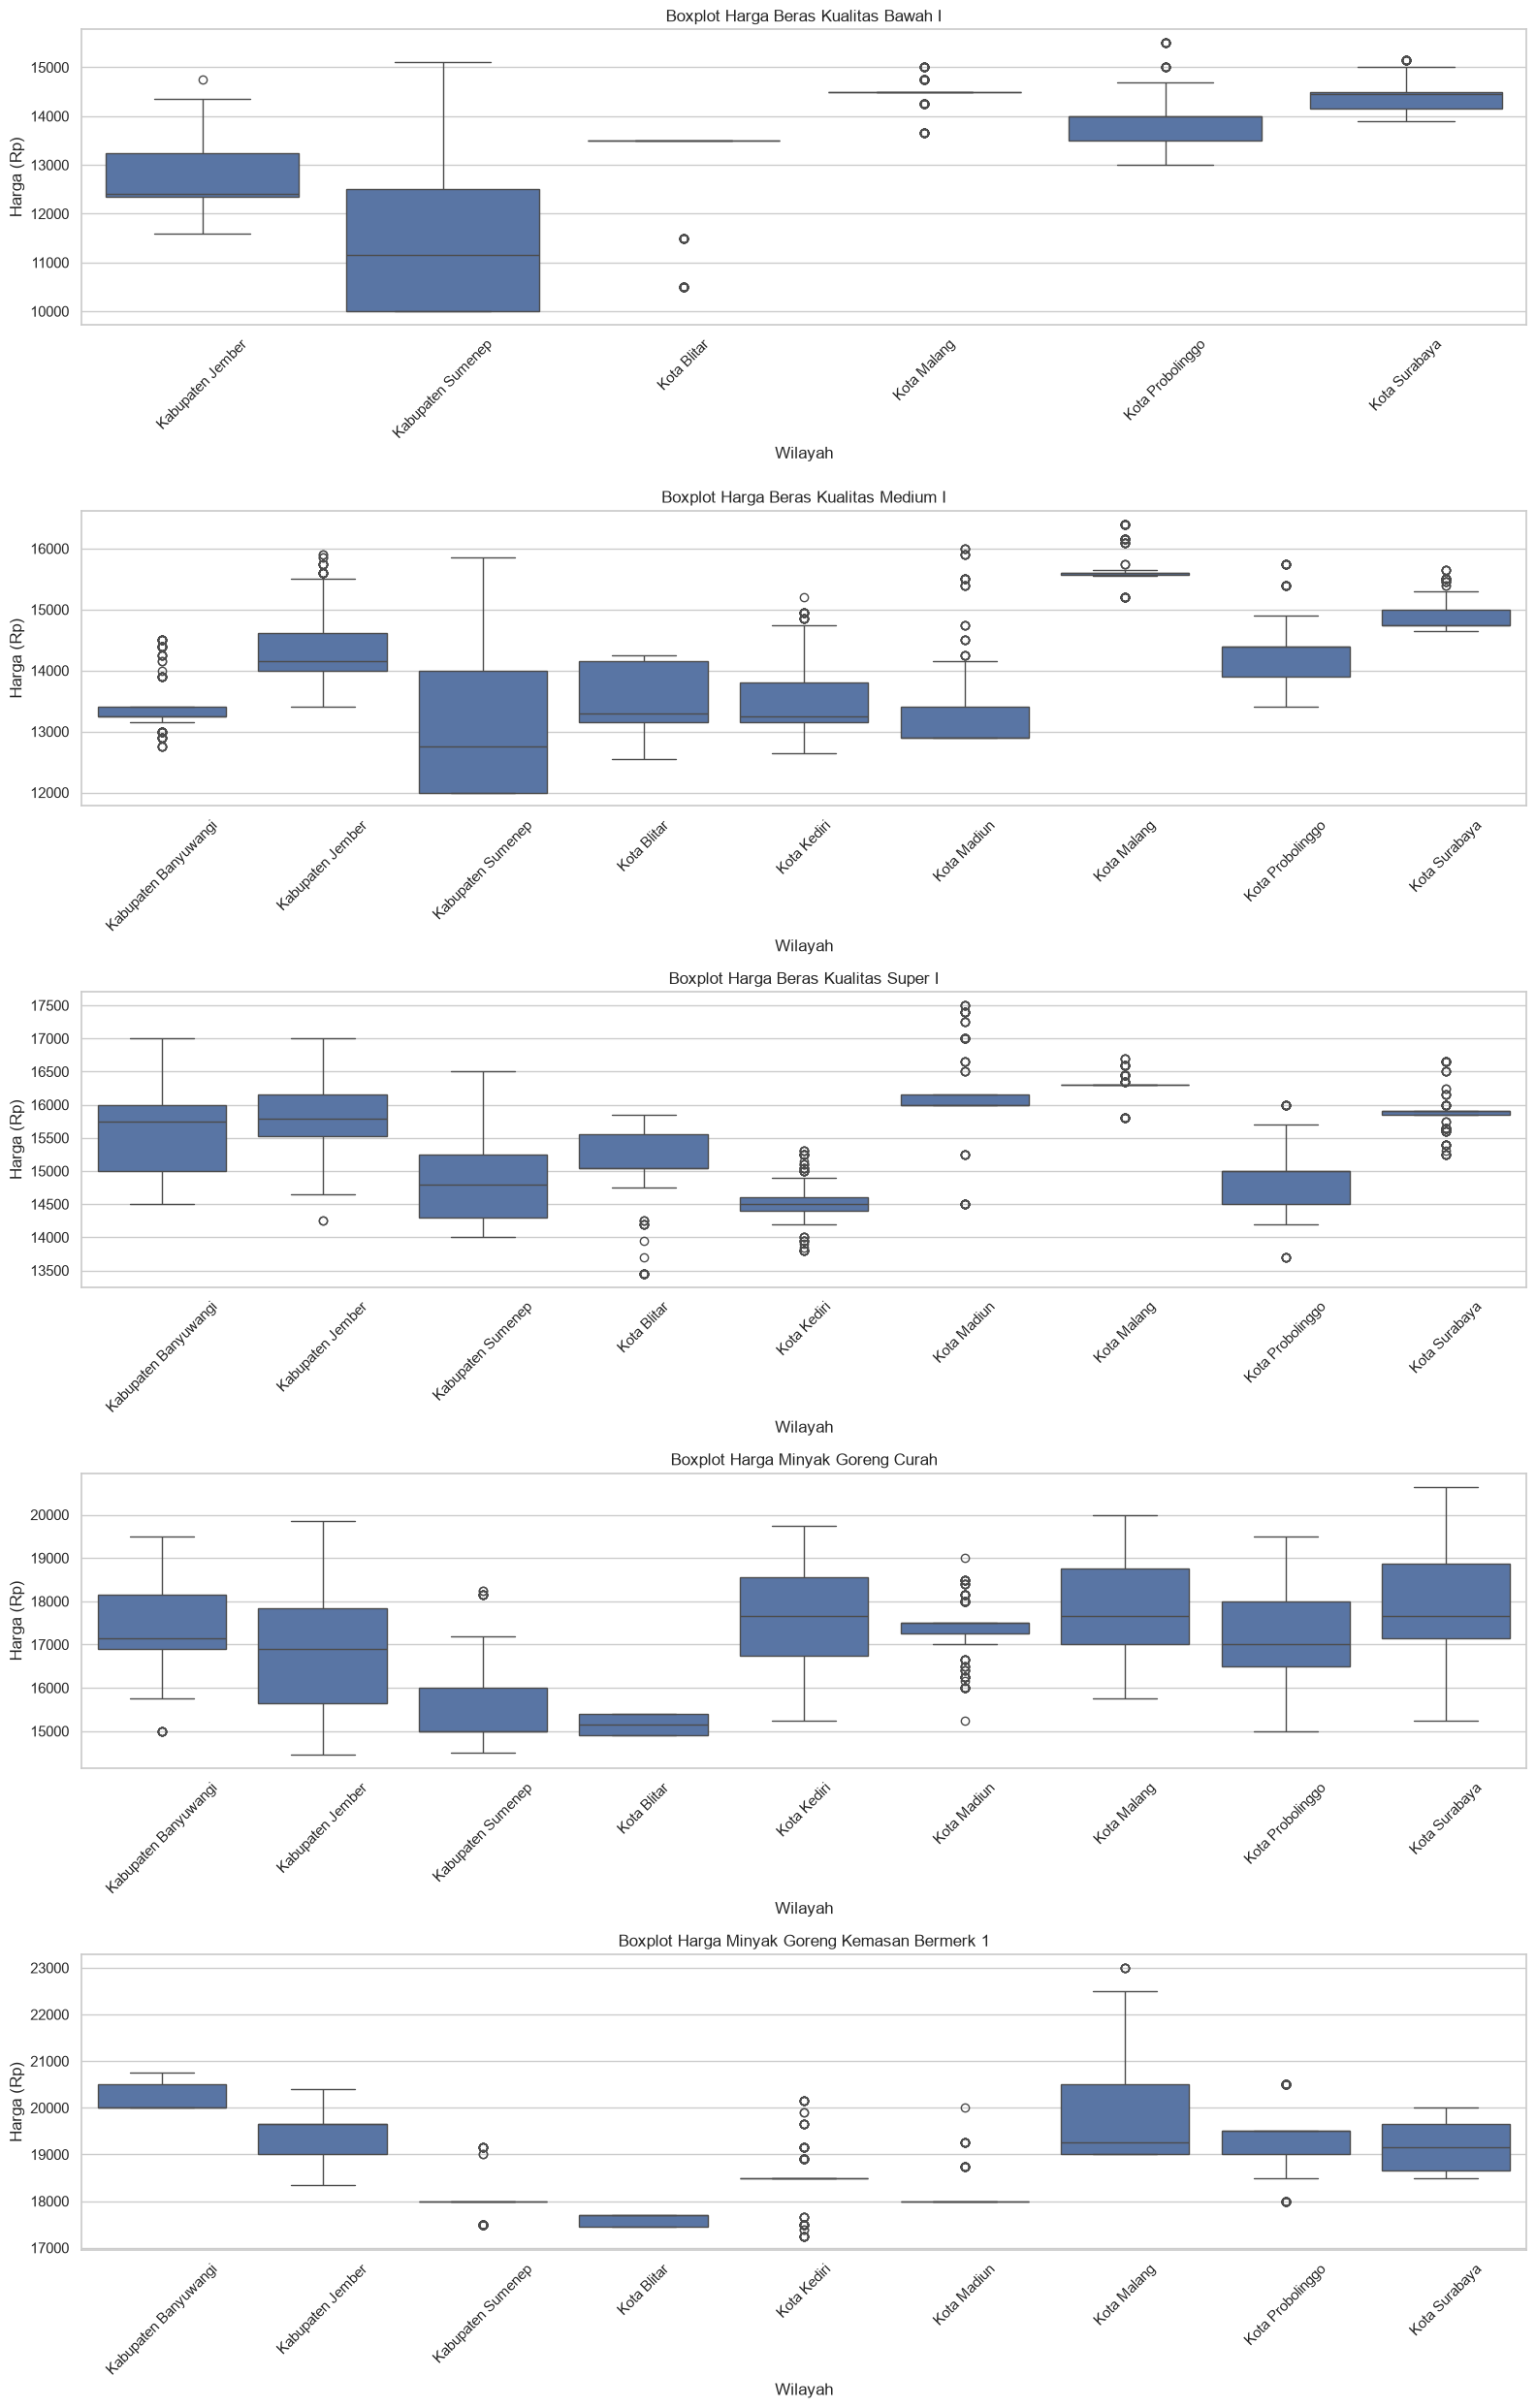

In [82]:
fig, axes = plt.subplots(
    nrows=len(komoditas_paket_d),
    ncols=1,
    figsize=(16, 25)
)

for ax, komoditas in zip(axes, komoditas_paket_d):

    data_plot = data_outlier[
        data_outlier["komoditas"] == komoditas
    ]

    sns.boxplot(
        data=data_plot,
        x="wilayah",
        y="harga",
        ax=ax
    )

    ax.set_title(f"Boxplot Harga {komoditas}")
    ax.set_xlabel("Wilayah")
    ax.set_ylabel("Harga (Rp)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [83]:
data_outlier["mean"] = (
    data_outlier.groupby(kelompok)["harga"]
    .transform("mean")
)

data_outlier["std"] = (
    data_outlier.groupby(kelompok)["harga"]
    .transform("std")
)

data_outlier["z_score"] = (
    (data_outlier["harga"] - data_outlier["mean"])
    / data_outlier["std"]
)

data_outlier["outlier_zscore"] = (
    data_outlier["z_score"].abs() > 3
)

perbandingan_outlier = (
    data_outlier.groupby(kelompok)
    .agg(
        total_data=("harga", "count"),
        outlier_IQR=("outlier_IQR", "sum"),
        outlier_Zscore=("outlier_zscore", "sum")
    )
    .reset_index()
)

display(perbandingan_outlier)

,wilayah,komoditas,total_data,outlier_IQR,outlier_Zscore
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,262,96,0
1,Kabupaten Banyuwangi,Beras Kualitas Super I,262,0,0
2,Kabupaten Banyuwangi,Minyak Goreng Curah,262,8,0
3,Kabupaten Banyuwangi,Minyak Goreng Kemasan Bermerk 1,262,0,0
4,Kabupaten Jember,Beras Kualitas Bawah I,262,1,0
5,Kabupaten Jember,Beras Kualitas Medium I,262,24,0
6,Kabupaten Jember,Beras Kualitas Super I,262,2,0
7,Kabupaten Jember,Minyak Goreng Curah,262,0,0
8,Kabupaten Jember,Minyak Goreng Kemasan Bermerk 1,262,0,0
9,Kabupaten Sumenep,Beras Kualitas Bawah I,262,0,0


In [84]:
detail_outlier = data_outlier[
    data_outlier["outlier_IQR"] |
    data_outlier["outlier_zscore"]
][
    [
        "wilayah",
        "komoditas",
        "tanggal",
        "harga",
        "z_score",
        "outlier_IQR",
        "outlier_zscore"
    ]
].sort_values(
    ["wilayah", "komoditas", "tanggal"]
)

display(detail_outlier)

print("Total data terdeteksi:", len(detail_outlier))
print(
    "Terdeteksi IQR:",
    data_outlier["outlier_IQR"].sum()
)
print(
    "Terdeteksi Z-score:",
    data_outlier["outlier_zscore"].sum()
)

,wilayah,komoditas,tanggal,harga,z_score,outlier_IQR,outlier_zscore
524,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-01,12900.0,-1.214227,True,False
525,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-02,12900.0,-1.214227,True,False
526,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-03,12900.0,-1.214227,True,False
527,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-04,12900.0,-1.214227,True,False
528,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-05,12900.0,-1.214227,True,False
...,...,...,...,...,...,...,...
42316,Kota Surabaya,Beras Kualitas Super I,2024-07-05,15650.0,-0.812111,True,False
42317,Kota Surabaya,Beras Kualitas Super I,2024-07-08,15650.0,-0.812111,True,False
42318,Kota Surabaya,Beras Kualitas Super I,2024-07-09,15750.0,-0.477299,True,False
42319,Kota Surabaya,Beras Kualitas Super I,2024-07-10,15750.0,-0.477299,True,False


Total data terdeteksi: 1345
Terdeteksi IQR: 1345
Terdeteksi Z-score: 28


In [85]:
evaluasi_iqr = (
    data_outlier.groupby(["wilayah", "komoditas"])
    .agg(
        total_data=("harga", "count"),
        harga_min=("harga", "min"),
        harga_max=("harga", "max"),
        Q1=("Q1", "first"),
        Q3=("Q3", "first"),
        IQR=("IQR", "first"),
        batas_bawah=("batas_bawah", "first"),
        batas_atas=("batas_atas", "first"),
        jumlah_outlier=("outlier_IQR", "sum")
    )
    .reset_index()
)

evaluasi_iqr = evaluasi_iqr.sort_values(
    "jumlah_outlier", ascending=False
)

display(evaluasi_iqr.head(15))

,wilayah,komoditas,total_data,harga_min,harga_max,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier
25,Kota Madiun,Minyak Goreng Curah,262,15250.0,19000.0,17250.0,17500.0,250.0,16875.00,17875.00,117
27,Kota Malang,Beras Kualitas Bawah I,262,13650.0,15000.0,14500.0,14500.0,0.0,14500.00,14500.00,114
39,Kota Surabaya,Beras Kualitas Super I,262,15250.0,16650.0,15850.0,15900.0,50.0,15775.00,15975.00,110
22,Kota Kediri,Minyak Goreng Kemasan Bermerk 1,262,17250.0,20150.0,18500.0,18500.0,0.0,18500.00,18500.00,100
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,262,12750.0,14500.0,13250.0,13400.0,150.0,13025.00,13625.00,96
24,Kota Madiun,Beras Kualitas Super I,262,14500.0,17500.0,16000.0,16150.0,150.0,15775.00,16375.00,80
29,Kota Malang,Beras Kualitas Super I,262,15800.0,16700.0,16300.0,16300.0,0.0,16300.00,16300.00,80
36,Kota Probolinggo,Minyak Goreng Kemasan Bermerk 1,262,18000.0,20500.0,19000.0,19500.0,500.0,18250.00,20250.00,79
28,Kota Malang,Beras Kualitas Medium I,262,15200.0,16400.0,15562.5,15600.0,37.5,15506.25,15656.25,78
13,Kabupaten Sumenep,Minyak Goreng Kemasan Bermerk 1,262,17500.0,19150.0,18000.0,18000.0,0.0,18000.00,18000.00,63


In [86]:
evaluasi_iqr["persentase_outlier"] = (
    evaluasi_iqr["jumlah_outlier"]
    / evaluasi_iqr["total_data"] * 100
)

kelompok_iqr_nol = evaluasi_iqr[
    evaluasi_iqr["IQR"] == 0
]

kelompok_iqr_positif = evaluasi_iqr[
    evaluasi_iqr["IQR"] > 0
]

print("Jumlah kelompok dengan IQR = 0:",
      len(kelompok_iqr_nol))

print("Jumlah kelompok dengan IQR > 0:",
      len(kelompok_iqr_positif))

print("\nKelompok dengan IQR = 0:")
display(
    kelompok_iqr_nol[
        [
            "wilayah",
            "komoditas",
            "Q1",
            "Q3",
            "IQR",
            "jumlah_outlier",
            "persentase_outlier"
        ]
    ]
)

Jumlah kelompok dengan IQR = 0: 6
Jumlah kelompok dengan IQR > 0: 36

Kelompok dengan IQR = 0:


,wilayah,komoditas,Q1,Q3,IQR,jumlah_outlier,persentase_outlier
27,Kota Malang,Beras Kualitas Bawah I,14500.0,14500.0,0.0,114,43.511450
22,Kota Kediri,Minyak Goreng Kemasan Bermerk 1,18500.0,18500.0,0.0,100,38.167939
29,Kota Malang,Beras Kualitas Super I,16300.0,16300.0,0.0,80,30.534351
13,Kabupaten Sumenep,Minyak Goreng Kemasan Bermerk 1,18000.0,18000.0,0.0,63,24.045802
14,Kota Blitar,Beras Kualitas Bawah I,13500.0,13500.0,0.0,55,20.992366
26,Kota Madiun,Minyak Goreng Kemasan Bermerk 1,18000.0,18000.0,0.0,31,11.832061


In [87]:
data_outlier["status_outlier"] = "Normal"

data_outlier.loc[
    data_outlier["outlier_IQR"] &
    ~data_outlier["outlier_zscore"],
    "status_outlier"
] = "IQR saja"

data_outlier.loc[
    ~data_outlier["outlier_IQR"] &
    data_outlier["outlier_zscore"],
    "status_outlier"
] = "Z-score saja"

data_outlier.loc[
    data_outlier["outlier_IQR"] &
    data_outlier["outlier_zscore"],
    "status_outlier"
] = "IQR dan Z-score"

ringkasan_status = (
    data_outlier["status_outlier"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="jumlah_data")
)

ringkasan_status["persentase"] = (
    ringkasan_status["jumlah_data"]
    / len(data_outlier) * 100
)

display(ringkasan_status)

,status,jumlah_data,persentase
0,Normal,9659,87.777172
1,IQR saja,1317,11.968375
2,IQR dan Z-score,28,0.254453


### Tahap 6c. Transformasi Data

In [88]:
data_transformasi = dataset_paket_d_clean[
    dataset_paket_d_clean["komoditas"].isin(komoditas_paket_d)
].copy()

harga_min = data_transformasi.groupby(
    "komoditas"
)["harga"].transform("min")

harga_max = data_transformasi.groupby(
    "komoditas"
)["harga"].transform("max")

data_transformasi["harga_normalisasi"] = (
    (data_transformasi["harga"] - harga_min)
    / (harga_max - harga_min)
)

display(
    data_transformasi[
        [
            "wilayah",
            "komoditas",
            "tanggal",
            "harga",
            "harga_normalisasi"
        ]
    ].head(10)
)

,wilayah,komoditas,tanggal,harga,harga_normalisasi
524,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-01,12900.0,0.204545
525,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-02,12900.0,0.204545
526,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-03,12900.0,0.204545
527,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-04,12900.0,0.204545
528,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-05,12900.0,0.204545
529,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-08,12900.0,0.204545
530,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-09,12900.0,0.204545
531,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-10,12900.0,0.204545
532,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-11,12900.0,0.204545
533,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01-12,12900.0,0.204545


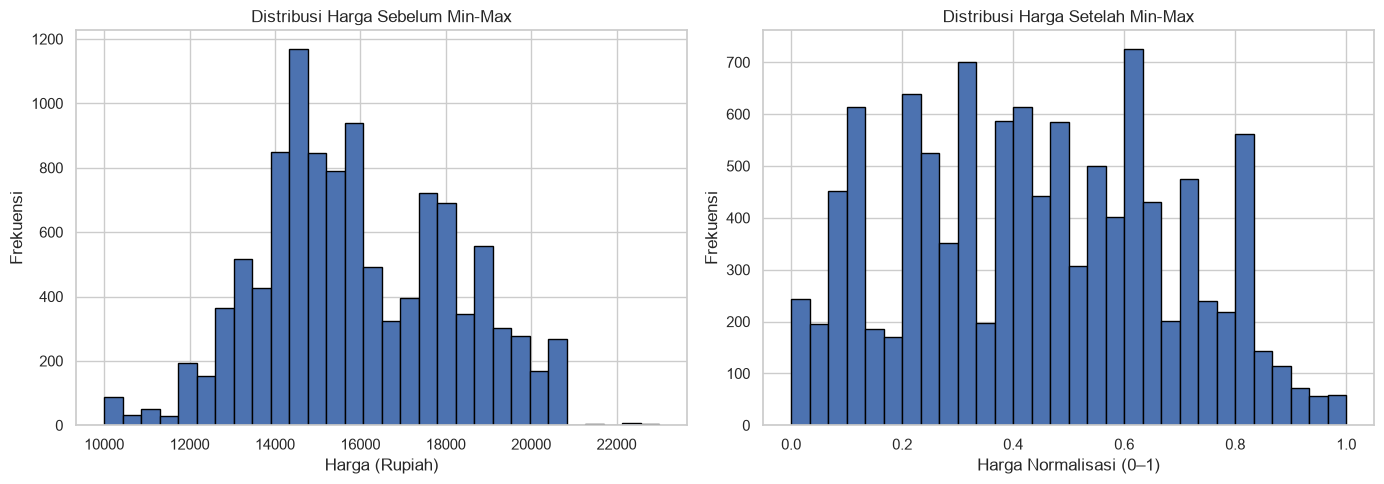

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    data_transformasi["harga"].dropna(),
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Distribusi Harga Sebelum Min-Max")
axes[0].set_xlabel("Harga (Rupiah)")
axes[0].set_ylabel("Frekuensi")

axes[1].hist(
    data_transformasi["harga_normalisasi"].dropna(),
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Distribusi Harga Setelah Min-Max")
axes[1].set_xlabel("Harga Normalisasi (0–1)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

## Tahap 7. Pemrosesan Data dalam Grup dan Jawaban Pertanyaan

### Tahap 7a. GroupBy dan agregasi beberapa fungsi

In [90]:
data_grup = dataset_paket_d_clean[
    dataset_paket_d_clean["komoditas"].isin(komoditas_paket_d)
].copy()

ringkasan_harga = (
    data_grup
    .groupby(["wilayah", "komoditas"])["harga"]
    .agg(
        jumlah_data="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max",
        standar_deviasi="std"
    )
    .reset_index()
)

display(ringkasan_harga.head(15))

print("Jumlah kelompok:", len(ringkasan_harga))

,wilayah,komoditas,jumlah_data,rata_rata,median,minimum,maksimum,standar_deviasi
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,262,13473.377863,13250.0,12750.0,14500.0,472.216326
1,Kabupaten Banyuwangi,Beras Kualitas Super I,262,15658.396947,15750.0,14500.0,17000.0,682.432899
2,Kabupaten Banyuwangi,Minyak Goreng Curah,262,17321.087786,17150.0,15000.0,19500.0,1047.669581
3,Kabupaten Banyuwangi,Minyak Goreng Kemasan Bermerk 1,262,20285.305344,20000.0,20000.0,20750.0,310.178082
4,Kabupaten Jember,Beras Kualitas Bawah I,262,12792.175573,12400.0,11600.0,14750.0,699.661823
5,Kabupaten Jember,Beras Kualitas Medium I,262,14429.675573,14150.0,13400.0,15900.0,619.749663
6,Kabupaten Jember,Beras Kualitas Super I,262,15813.454198,15787.5,14250.0,17000.0,551.723871
7,Kabupaten Jember,Minyak Goreng Curah,262,16897.041985,16900.0,14450.0,19850.0,1362.842748
8,Kabupaten Jember,Minyak Goreng Kemasan Bermerk 1,262,19417.366412,19650.0,18350.0,20400.0,423.873232
9,Kabupaten Sumenep,Beras Kualitas Bawah I,262,11685.877863,11150.0,10000.0,15100.0,1590.450126


Jumlah kelompok: 42


In [91]:
data_grup["bulan"] = (
    data_grup["tanggal"]
    .dt.to_period("M")
    .astype(str)
)

harga_bulanan = (
    data_grup
    .groupby(["wilayah", "komoditas", "bulan"])["harga"]
    .agg(
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max",
        jumlah_data="count"
    )
    .reset_index()
)

display(harga_bulanan.head(15))

print("Jumlah kelompok bulanan:", len(harga_bulanan))
print(
    "Periode:",
    harga_bulanan["bulan"].min(),
    "sampai",
    harga_bulanan["bulan"].max()
)

,wilayah,komoditas,bulan,rata_rata,median,minimum,maksimum,jumlah_data
0,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-01,13032.608696,13000.0,12900.0,13400.0,23
1,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-02,14047.619048,13900.0,13400.0,14500.0,21
2,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-03,14442.857143,14400.0,14400.0,14500.0,21
3,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-04,14052.272727,14325.0,13250.0,14400.0,22
4,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-05,13086.956522,13000.0,13000.0,13250.0,23
5,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-06,13267.500000,13400.0,12750.0,14000.0,20
6,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-07,13400.000000,13400.0,13400.0,13400.0,23
7,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-08,13400.000000,13400.0,13400.0,13400.0,22
8,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-09,13285.714286,13250.0,13250.0,13400.0,21
9,Kabupaten Banyuwangi,Beras Kualitas Medium I,2024-10,13250.000000,13250.0,13250.0,13250.0,23


Jumlah kelompok bulanan: 504
Periode: 2024-01 sampai 2024-12


In [92]:
pivot_harga = harga_bulanan.pivot_table(
    index=["wilayah", "bulan"],
    columns="komoditas",
    values="rata_rata"
).reset_index()

pivot_harga["selisih_medium_bawah"] = (
    pivot_harga["Beras Kualitas Medium I"]
    - pivot_harga["Beras Kualitas Bawah I"]
)

pivot_harga["selisih_super_medium"] = (
    pivot_harga["Beras Kualitas Super I"]
    - pivot_harga["Beras Kualitas Medium I"]
)

pivot_harga["selisih_kemasan_curah"] = (
    pivot_harga["Minyak Goreng Kemasan Bermerk 1"]
    - pivot_harga["Minyak Goreng Curah"]
)

display(
    pivot_harga[
        [
            "wilayah",
            "bulan",
            "selisih_medium_bawah",
            "selisih_super_medium",
            "selisih_kemasan_curah"
        ]
    ].head(15)
)

print("Jumlah baris:", len(pivot_harga))

komoditas,wilayah,bulan,selisih_medium_bawah,selisih_super_medium,selisih_kemasan_curah
0,Kabupaten Banyuwangi,2024-01,NaN,1923.913043,5206.521739
1,Kabupaten Banyuwangi,2024-02,NaN,2333.333333,4742.857143
2,Kabupaten Banyuwangi,2024-03,NaN,2509.523810,3971.428571
3,Kabupaten Banyuwangi,2024-04,NaN,2129.545455,3500.000000
4,Kabupaten Banyuwangi,2024-05,NaN,2173.913043,3500.000000
5,Kabupaten Banyuwangi,2024-06,NaN,2420.000000,3256.250000
6,Kabupaten Banyuwangi,2024-07,NaN,2600.000000,2682.608696
7,Kabupaten Banyuwangi,2024-08,NaN,2520.454545,2600.000000
8,Kabupaten Banyuwangi,2024-09,NaN,2297.619048,2028.571429
9,Kabupaten Banyuwangi,2024-10,NaN,1847.826087,1850.000000


Jumlah baris: 108


In [93]:
pivot_harga = pivot_harga.sort_values(
    ["wilayah", "bulan"]
).copy()

kolom_selisih = [
    "selisih_medium_bawah",
    "selisih_super_medium",
    "selisih_kemasan_curah"
]

for kolom in kolom_selisih:
    nama_baru = "perubahan_" + kolom

    pivot_harga[nama_baru] = (
        pivot_harga
        .groupby("wilayah")[kolom]
        .pct_change(fill_method=None) * 100
    )

display(
    pivot_harga[
        [
            "wilayah",
            "bulan",
            "selisih_medium_bawah",
            "perubahan_selisih_medium_bawah",
            "selisih_super_medium",
            "perubahan_selisih_super_medium",
            "selisih_kemasan_curah",
            "perubahan_selisih_kemasan_curah"
        ]
    ].head(15)
)

komoditas,wilayah,bulan,selisih_medium_bawah,perubahan_selisih_medium_bawah,selisih_super_medium,perubahan_selisih_super_medium,selisih_kemasan_curah,perubahan_selisih_kemasan_curah
0,Kabupaten Banyuwangi,2024-01,NaN,NaN,1923.913043,NaN,5206.521739,NaN
1,Kabupaten Banyuwangi,2024-02,NaN,NaN,2333.333333,21.280603,4742.857143,-8.905458
2,Kabupaten Banyuwangi,2024-03,NaN,NaN,2509.523810,7.551020,3971.428571,-16.265060
3,Kabupaten Banyuwangi,2024-04,NaN,NaN,2129.545455,-15.141452,3500.000000,-11.870504
4,Kabupaten Banyuwangi,2024-05,NaN,NaN,2173.913043,2.083430,3500.000000,0.000000
5,Kabupaten Banyuwangi,2024-06,NaN,NaN,2420.000000,11.320000,3256.250000,-6.964286
6,Kabupaten Banyuwangi,2024-07,NaN,NaN,2600.000000,7.438017,2682.608696,-17.616624
7,Kabupaten Banyuwangi,2024-08,NaN,NaN,2520.454545,-3.059441,2600.000000,-3.079417
8,Kabupaten Banyuwangi,2024-09,NaN,NaN,2297.619048,-8.841084,2028.571429,-21.978022
9,Kabupaten Banyuwangi,2024-10,NaN,NaN,1847.826087,-19.576481,1850.000000,-8.802817


In [94]:
ringkasan_selisih = (
    pivot_harga
    .groupby("wilayah")[
        [
            "selisih_medium_bawah",
            "selisih_super_medium",
            "selisih_kemasan_curah"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
)

display(ringkasan_selisih)

komoditas            selisih_medium_bawah                            \
                                     mean          std          min   
wilayah                                                               
Kabupaten Banyuwangi                  NaN          NaN          NaN   
Kabupaten Jember              1641.550952   259.092028  1139.130435   
Kabupaten Sumenep             1486.098171   426.911011   900.000000   
Kota Blitar                    571.697958  1011.774864  -350.000000   
Kota Kediri                           NaN          NaN          NaN   
Kota Madiun                           NaN          NaN          NaN   
Kota Malang                   1218.490024   159.552677  1050.000000   
Kota Probolinggo               383.592133    43.208576   250.000000   
Kota Surabaya                  476.051078   236.536460   250.000000   

komoditas                         selisih_super_medium              \
                              max                 mean         std   
wilayah                                                              
Kabupaten Banyuwangi          NaN          2188.064810  307.932745   
Kabupaten Jember      2045.000000          1382.172697  285.068688   
Kabupaten Sumenep     2000.000000          1840.576573  752.426609   
Kota Blitar           2509.523810          1554.202742  389.547752   
Kota Kediri                   NaN           998.628757  473.167654   
Kota Madiun                   NaN          2790.725971  714.164220   
Kota Malang           1543.478261           606.586047  179.969440   
Kota Probolinggo       400.000000           469.523810  149.510306   
Kota Surabaya          956.521739           995.887054  169.618114   

komoditas                                      selisih_kemasan_curah  \
                              min          max                  mean   
wilayah                                                                
Kabupaten Banyuwangi  1739.285714  2600.000000           2961.880548   
Kabupaten Jember       834.090909  1831.818182           2515.992338   
Kabupaten Sumenep      650.000000  2592.857143           2372.014791   
Kota Blitar            900.000000  1990.909091           2433.152174   
Kota Kediri            243.478261  1500.000000            895.933598   
Kota Madiun           1167.391304  3250.000000            736.590282   
Kota Malang            216.666667   750.000000           2075.678760   
Kota Probolinggo       269.047619   600.000000           2256.132952   
Kota Surabaya          673.913043  1150.000000           1446.703565   

komoditas                                                    
                              std          min          max  
wilayah                                                      
Kabupaten Banyuwangi  1321.267102   909.090909  5206.521739  
Kabupaten Jember      1204.584813   640.909091  3882.608696  
Kabupaten Sumenep      810.430900   845.238095  3000.000000  
Kota Blitar            124.978517  2300.000000  2550.000000  
Kota Kediri            641.092736    33.333333  1797.500000  
Kota Madiun            574.402111    21.739130  1956.521739  
Kota Malang           1427.441863   -47.619048  4684.782609  
Kota Probolinggo       532.413987  1318.181818  2913.043478  
Kota Surabaya         1606.155998  -490.909091  4210.869565

### Tahap 7b. Menjawab pertanyaan Paket D

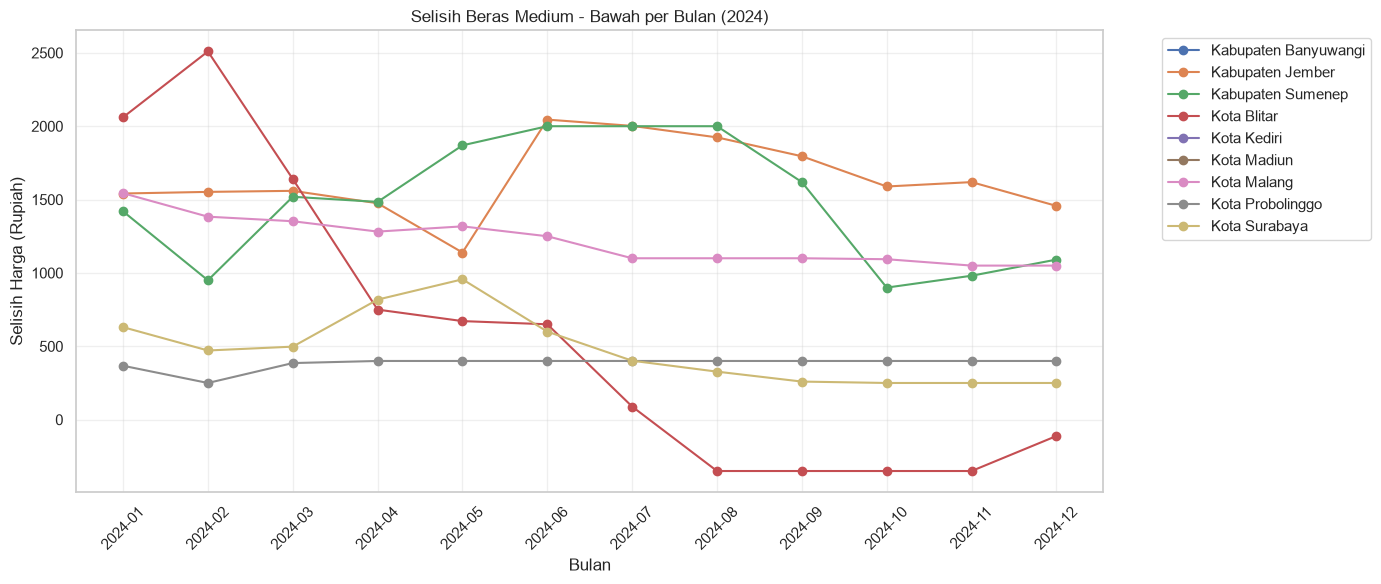

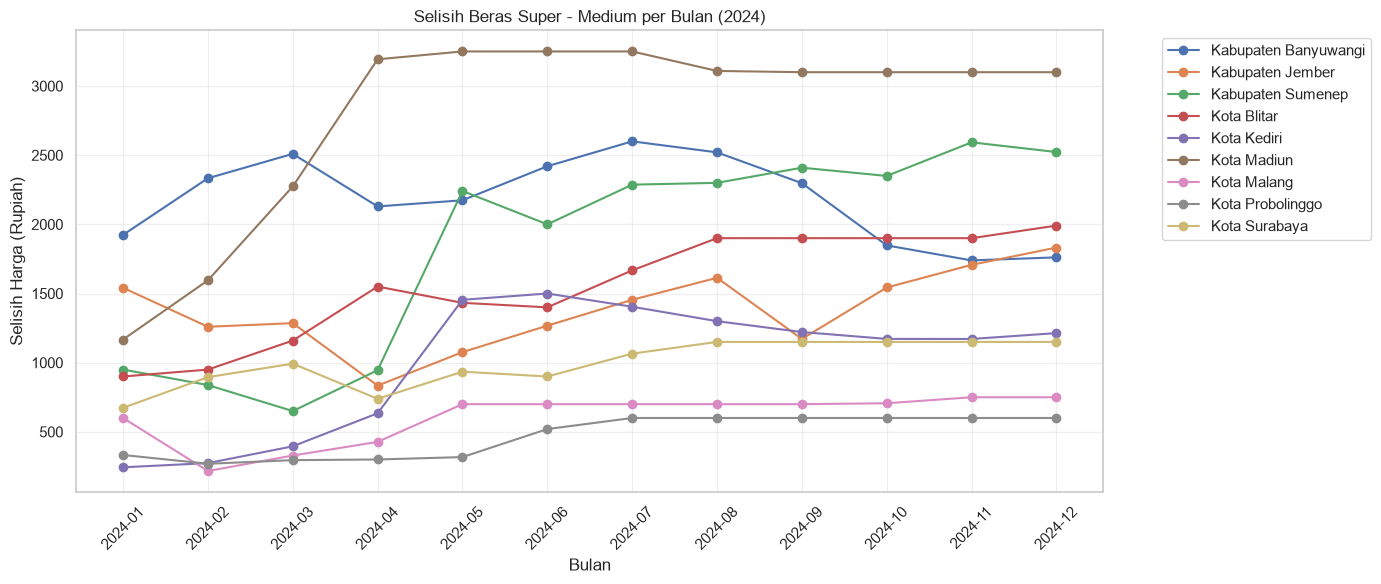

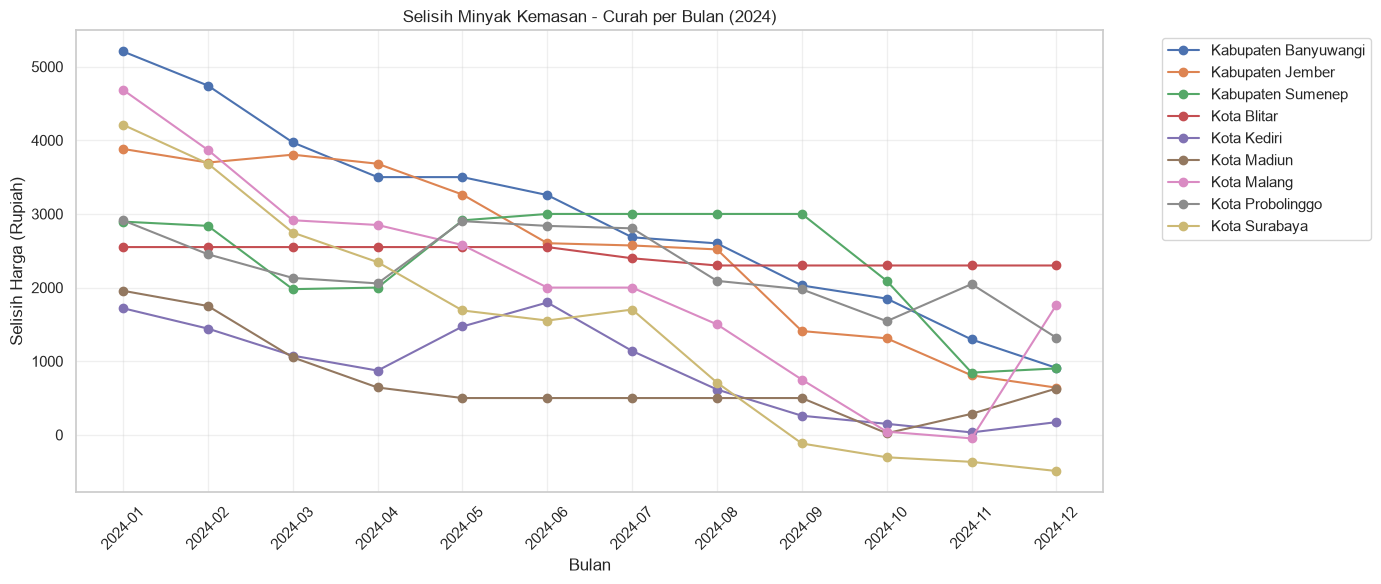

In [95]:
kolom_grafik = [
    ("selisih_medium_bawah", "Selisih Beras Medium - Bawah"),
    ("selisih_super_medium", "Selisih Beras Super - Medium"),
    ("selisih_kemasan_curah", "Selisih Minyak Kemasan - Curah")
]

for kolom, judul in kolom_grafik:
    plt.figure(figsize=(14, 6))

    for wilayah in pivot_harga["wilayah"].unique():
        data_wilayah = pivot_harga[
            pivot_harga["wilayah"] == wilayah
        ]

        plt.plot(
            data_wilayah["bulan"],
            data_wilayah[kolom],
            marker="o",
            label=wilayah
        )

    plt.title(judul + " per Bulan (2024)")
    plt.xlabel("Bulan")
    plt.ylabel("Selisih Harga (Rupiah)")
    plt.xticks(rotation=45)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [96]:
ringkasan_selisih_rapi = ringkasan_selisih.copy()

ringkasan_selisih_rapi.columns = [
    f"{kolom}_{statistik}"
    for kolom, statistik in ringkasan_selisih_rapi.columns
]

ringkasan_selisih_rapi = ringkasan_selisih_rapi.reset_index()

display(
    ringkasan_selisih_rapi.round(2)
)

,wilayah,selisih_medium_bawah_mean,selisih_medium_bawah_std,selisih_medium_bawah_min,selisih_medium_bawah_max,selisih_super_medium_mean,selisih_super_medium_std,selisih_super_medium_min,selisih_super_medium_max,selisih_kemasan_curah_mean,selisih_kemasan_curah_std,selisih_kemasan_curah_min,selisih_kemasan_curah_max
0,Kabupaten Banyuwangi,NaN,NaN,NaN,NaN,2188.06,307.93,1739.29,2600.00,2961.88,1321.27,909.09,5206.52
1,Kabupaten Jember,1641.55,259.09,1139.13,2045.00,1382.17,285.07,834.09,1831.82,2515.99,1204.58,640.91,3882.61
2,Kabupaten Sumenep,1486.10,426.91,900.00,2000.00,1840.58,752.43,650.00,2592.86,2372.01,810.43,845.24,3000.00
3,Kota Blitar,571.70,1011.77,-350.00,2509.52,1554.20,389.55,900.00,1990.91,2433.15,124.98,2300.00,2550.00
4,Kota Kediri,NaN,NaN,NaN,NaN,998.63,473.17,243.48,1500.00,895.93,641.09,33.33,1797.50
5,Kota Madiun,NaN,NaN,NaN,NaN,2790.73,714.16,1167.39,3250.00,736.59,574.40,21.74,1956.52
6,Kota Malang,1218.49,159.55,1050.00,1543.48,606.59,179.97,216.67,750.00,2075.68,1427.44,-47.62,4684.78
7,Kota Probolinggo,383.59,43.21,250.00,400.00,469.52,149.51,269.05,600.00,2256.13,532.41,1318.18,2913.04
8,Kota Surabaya,476.05,236.54,250.00,956.52,995.89,169.62,673.91,1150.00,1446.70,1606.16,-490.91,4210.87


In [97]:
tabel_hasil = ringkasan_selisih_rapi.copy()

kolom_nilai = tabel_hasil.select_dtypes(include="number").columns

for kolom in kolom_nilai:
    tabel_hasil[kolom] = tabel_hasil[kolom].apply(
        lambda x: f"Rp{x:,.2f}" if pd.notna(x) else "-"
    )

display(tabel_hasil)

,wilayah,selisih_medium_bawah_mean,selisih_medium_bawah_std,selisih_medium_bawah_min,selisih_medium_bawah_max,selisih_super_medium_mean,selisih_super_medium_std,selisih_super_medium_min,selisih_super_medium_max,selisih_kemasan_curah_mean,selisih_kemasan_curah_std,selisih_kemasan_curah_min,selisih_kemasan_curah_max
0,Kabupaten Banyuwangi,-,-,-,-,"Rp2,188.06",Rp307.93,"Rp1,739.29","Rp2,600.00","Rp2,961.88","Rp1,321.27",Rp909.09,"Rp5,206.52"
1,Kabupaten Jember,"Rp1,641.55",Rp259.09,"Rp1,139.13","Rp2,045.00","Rp1,382.17",Rp285.07,Rp834.09,"Rp1,831.82","Rp2,515.99","Rp1,204.58",Rp640.91,"Rp3,882.61"
2,Kabupaten Sumenep,"Rp1,486.10",Rp426.91,Rp900.00,"Rp2,000.00","Rp1,840.58",Rp752.43,Rp650.00,"Rp2,592.86","Rp2,372.01",Rp810.43,Rp845.24,"Rp3,000.00"
3,Kota Blitar,Rp571.70,"Rp1,011.77",Rp-350.00,"Rp2,509.52","Rp1,554.20",Rp389.55,Rp900.00,"Rp1,990.91","Rp2,433.15",Rp124.98,"Rp2,300.00","Rp2,550.00"
4,Kota Kediri,-,-,-,-,Rp998.63,Rp473.17,Rp243.48,"Rp1,500.00",Rp895.93,Rp641.09,Rp33.33,"Rp1,797.50"
5,Kota Madiun,-,-,-,-,"Rp2,790.73",Rp714.16,"Rp1,167.39","Rp3,250.00",Rp736.59,Rp574.40,Rp21.74,"Rp1,956.52"
6,Kota Malang,"Rp1,218.49",Rp159.55,"Rp1,050.00","Rp1,543.48",Rp606.59,Rp179.97,Rp216.67,Rp750.00,"Rp2,075.68","Rp1,427.44",Rp-47.62,"Rp4,684.78"
7,Kota Probolinggo,Rp383.59,Rp43.21,Rp250.00,Rp400.00,Rp469.52,Rp149.51,Rp269.05,Rp600.00,"Rp2,256.13",Rp532.41,"Rp1,318.18","Rp2,913.04"
8,Kota Surabaya,Rp476.05,Rp236.54,Rp250.00,Rp956.52,Rp995.89,Rp169.62,Rp673.91,"Rp1,150.00","Rp1,446.70","Rp1,606.16",Rp-490.91,"Rp4,210.87"


## Tahap 8. Final Dataset

In [98]:
print("Ukuran dataset:", dataset_final.shape)
print("\nRentang tanggal:")
print(dataset_final["tanggal"].min(), "sampai", dataset_final["tanggal"].max())

print("\nKolom dataset:")
display(dataset_final.dtypes)

print("\nContoh data:")
display(dataset_final.head())

Ukuran dataset: (46112, 16)

Rentang tanggal:
2024-01-01 00:00:00 sampai 2024-12-31 00:00:00

Kolom dataset:


kategori                      string
komoditas                     string
tanggal               datetime64[us]
harga                        float64
kode                          object
wilayah                          str
jumlah_penduduk                int64
luas                         float64
jumlah_kecamatan               int64
jumlah_kelurahan               int64
jumlah_desa                    int64
kepadatan_penduduk           float64
TEMP_C                       float64
MAX_C                        float64
MIN_C                        float64
PRCP_MM                      float64
dtype: object


Contoh data:


,kategori,komoditas,tanggal,harga,kode,wilayah,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk,TEMP_C,MAX_C,MIN_C,PRCP_MM
0,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-01,33000.0,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.333333,33.277778,26.388889,0.000
1,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-02,33000.0,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,30.277778,34.777778,26.277778,0.000
2,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-03,32000.0,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.166667,33.388889,26.222222,0.000
3,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-04,33000.0,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,29.555556,33.000000,26.000000,0.254
4,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-05,33500.0,35.10,Kabupaten Banyuwangi,1791789,3593.849,25,28,189,498.571031,27.888889,31.611111,25.111111,3.302


In [99]:
data_harga_bersih = dataset_paket_d_clean.copy()

data_harga_bersih["tanggal_mulai_minggu"] = (
    data_harga_bersih["tanggal"]
    - pd.to_timedelta(data_harga_bersih["tanggal"].dt.weekday, unit="D")
)

harga_mingguan_df = (
    data_harga_bersih
    .groupby(
        ["kode", "wilayah", "kategori", "komoditas", "tanggal_mulai_minggu"],
        as_index=False
    )
    .agg(
        harga_mingguan=("harga", "mean"),
        jumlah_observasi_harga=("harga", "count"),
        jumlah_penduduk=("jumlah_penduduk", "first"),
        luas=("luas", "first"),
        jumlah_kecamatan=("jumlah_kecamatan", "first"),
        jumlah_kelurahan=("jumlah_kelurahan", "first"),
        jumlah_desa=("jumlah_desa", "first"),
        kepadatan_penduduk=("kepadatan_penduduk", "first")
    )
)

cuaca_mingguan_df = cuaca_harian.copy()

cuaca_mingguan_df["tanggal_mulai_minggu"] = (
    cuaca_mingguan_df["tanggal"]
    - pd.to_timedelta(cuaca_mingguan_df["tanggal"].dt.weekday, unit="D")
)

cuaca_mingguan_agg = (
    cuaca_mingguan_df
    .groupby(["kode", "tanggal_mulai_minggu"], as_index=False)
    .agg(
        TEMP_C=("TEMP_C", "mean"),
        MAX_C=("MAX_C", "mean"),
        MIN_C=("MIN_C", "mean"),
        PRCP_MM=("PRCP_MM", lambda x: x.sum(min_count=1))
    )
)

dataset_mingguan = harga_mingguan_df.merge(
    cuaca_mingguan_agg,
    on=["kode", "tanggal_mulai_minggu"],
    how="left",
    validate="many_to_one"
)

dataset_mingguan["tahun_iso"] = (
    dataset_mingguan["tanggal_mulai_minggu"].dt.isocalendar().year
)
dataset_mingguan["minggu_ke"] = (
    dataset_mingguan["tanggal_mulai_minggu"].dt.isocalendar().week
)

dataset_mingguan = dataset_mingguan[
    [
        "kode", "wilayah", "kategori", "komoditas",
        "tanggal_mulai_minggu", "tahun_iso", "minggu_ke",
        "harga_mingguan", "jumlah_observasi_harga",
        "jumlah_penduduk", "luas",
        "jumlah_kecamatan", "jumlah_kelurahan",
        "jumlah_desa", "kepadatan_penduduk",
        "TEMP_C", "MAX_C", "MIN_C", "PRCP_MM"
    ]
]

print("Ukuran dataset mingguan:", dataset_mingguan.shape)
print("\nRentang minggu:")
print(
    dataset_mingguan["tanggal_mulai_minggu"].min(),
    "sampai",
    dataset_mingguan["tanggal_mulai_minggu"].max()
)
print("\nJumlah minggu:", dataset_mingguan["tanggal_mulai_minggu"].nunique())
print("Jumlah missing harga_mingguan:", dataset_mingguan["harga_mingguan"].isna().sum())

display(dataset_mingguan.head(10))

Ukuran dataset mingguan: (9328, 19)

Rentang minggu:
2024-01-01 00:00:00 sampai 2024-12-30 00:00:00

Jumlah minggu: 53
Jumlah missing harga_mingguan: 16


,kode,wilayah,kategori,komoditas,tanggal_mulai_minggu,tahun_iso,minggu_ke,harga_mingguan,jumlah_observasi_harga,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk,TEMP_C,MAX_C,MIN_C,PRCP_MM
0,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-01,2024,1,34860.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
1,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-08,2024,2,37650.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
2,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-15,2024,3,37310.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
3,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-22,2024,4,34870.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
4,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-01-29,2024,5,34520.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
5,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-02-05,2024,6,30460.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
6,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-02-12,2024,7,29860.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
7,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-02-19,2024,8,31060.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
8,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-02-26,2024,9,30970.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
9,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-03-04,2024,10,32590.0,5,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN


In [100]:
print("Jumlah periode mingguan:",
      dataset_mingguan["tanggal_mulai_minggu"].nunique())

print("\nDistribusi tahun ISO:")
display(
    dataset_mingguan.groupby("tahun_iso")["minggu_ke"]
    .nunique()
)

print("\nPeriode minggu terakhir:")
display(
    dataset_mingguan[
        dataset_mingguan["tanggal_mulai_minggu"]
        == dataset_mingguan["tanggal_mulai_minggu"].max()
    ].head()
)

print("\nPemeriksaan duplikasi:")
print(
    "Duplikasi:",
    dataset_mingguan.duplicated(
        subset=[
            "kode", "komoditas", "tanggal_mulai_minggu"
        ]
    ).sum()
)

print("\nJumlah harga mingguan kosong:",
      dataset_mingguan["harga_mingguan"].isna().sum())

print("\nJumlah observasi harga per minggu:")
display(
    dataset_mingguan["jumlah_observasi_harga"].value_counts().sort_index()
)

Jumlah periode mingguan: 53

Distribusi tahun ISO:


tahun_iso
2024    52
2025     1
Name: minggu_ke, dtype: int64


Periode minggu terakhir:


,kode,wilayah,kategori,komoditas,tanggal_mulai_minggu,tahun_iso,minggu_ke,harga_mingguan,jumlah_observasi_harga,jumlah_penduduk,luas,jumlah_kecamatan,jumlah_kelurahan,jumlah_desa,kepadatan_penduduk,TEMP_C,MAX_C,MIN_C,PRCP_MM
52,35.09,Kabupaten Jember,Bawang Merah,Bawang Merah Ukuran Sedang,2024-12-30,2025,1,37575.0,2,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
105,35.09,Kabupaten Jember,Bawang Putih,Bawang Putih Ukuran Sedang,2024-12-30,2025,1,35500.0,2,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
158,35.09,Kabupaten Jember,Beras,Beras Kualitas Bawah I,2024-12-30,2025,1,12750.0,2,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
211,35.09,Kabupaten Jember,Beras,Beras Kualitas Medium I,2024-12-30,2025,1,14150.0,2,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN
264,35.09,Kabupaten Jember,Beras,Beras Kualitas Super I,2024-12-30,2025,1,16000.0,2,2615874,3314.358,31,22,226,789.255114,NaN,NaN,NaN,NaN



Pemeriksaan duplikasi:
Duplikasi: 0

Jumlah harga mingguan kosong: 16

Jumlah observasi harga per minggu:


jumlah_observasi_harga
0      16
1       2
2     179
3      39
4     223
5    8869
Name: count, dtype: int64

In [101]:
dataset_paket_d_clean.to_csv(
    OUTPUT_DIR / "harga_pangan_jatim_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

dataset_mingguan.to_csv(
    OUTPUT_DIR / "harga_pangan_jatim_mingguan_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset harian (bersih) dan mingguan berhasil disimpan di folder:", OUTPUT_DIR)

Dataset harian (bersih) dan mingguan berhasil disimpan di folder: data_processed
